# 7 Stationary Wavelet Transform (SWT)

## 7.5 1D SWT ImpImplementation in PyWavelets

### 7.5.1 1D SWT Functions

**4. Example: Lengths of Coefficients**

In [1]:
import pywt
import numpy as np

# A simple signal 
x = np.arange(16)

# Decompose using SWT
coeffs = pywt.swt(x, wavelet='db2', level=3)

# Each element is a tuple (approximation, detail)
for i, (cA, cD) in enumerate(coeffs[::-1], 1):
    print(f"Level {i}:")
    print(f"  A{i}: {cA}")
    print(f"  D{i}: {cD}")
    print()

Level 1:
  A1: [ 7.20976852  0.89657547  2.31078903  3.7250026   5.13921616  6.55342972
  7.96764328  9.38185685 10.79607041 12.21028397 13.62449753 15.0387111
 16.45292466 17.86713822 21.35190414 19.17981582]
  D1: [-2.07055236e+00 -2.77555756e-17  1.66533454e-16  1.11022302e-16
  3.33066907e-16  4.44089210e-16  2.22044605e-16  0.00000000e+00
  2.22044605e-16  1.33226763e-15  4.44089210e-16  8.88178420e-16
  8.88178420e-16  4.44089210e-16  7.72740661e+00 -5.65685425e+00]

Level 2:
  A2: [16.19615242 10.          5.53589838  3.80384758  5.80384758  7.80384758
  9.80384758 11.80384758 13.80384758 15.80384758 17.53589838 20.
 24.19615242 26.39230485 27.12435565 24.39230485]
  D2: [-4.92820323e+00 -2.73205081e+00 -1.00000000e+00 -5.55111512e-17
  7.21644966e-16 -5.55111512e-17 -2.22044605e-16  9.99200722e-16
  1.11022302e-15 -1.77635684e-15 -1.00000000e+00  7.32050808e-01
  8.92820323e+00  9.66025404e+00 -2.00000000e+00 -7.66025404e+00]

Level 3:
  A3: [24.74873734 20.81568368 17.65908716

In [ ]:
# Check lengths at each decomposition level
for i, (cA, cD) in enumerate(coeffs[::-1], 1):
    print(f"Original signal length: {len(x)}\n")
    print(f"Level {i}:")
    print(f"  Approximation (A{i}) length: {len(cA)}")
    print(f"  Detail (D{i}) length:        {len(cD)}\n")

Original signal length: 16

Level 1:
  Approximation (A1) length: 16
  Detail (D1) length:        16

Original signal length: 16

Level 2:
  Approximation (A2) length: 16
  Detail (D2) length:        16

Original signal length: 16

Level 3:
  Approximation (A3) length: 16
  Detail (D3) length:        16



### 7.5.2 Maximum Decomposition Level

**3. Example: Calculate Maximum Decomposition Level**

In [2]:
import pywt
import numpy as np

# Create a test signal
S = np.arange(1, 17)  # Length = 16
print(f"Signal: {S}")
print(f"Signal length: {len(S)}")

# Calculate maximum decomposition level
max_level = pywt.swt_max_level(len(S))
print(f"Maximum decomposition level: {max_level}")

# Verify the calculation
import math
theoretical_max = int(math.log2(len(S)))
print(f"Theoretical maximum (⌊log₂({len(S)})⌋): {theoretical_max}")

Signal: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16]
Signal length: 16
Maximum decomposition level: 4
Theoretical maximum (⌊log₂(16)⌋): 4


**3. Decomposing to Maximum Level*

In [3]:
# Perform maximum level decomposition
coeffs = pywt.swt(S, 'db2', level=max_level)
print(f"Number of decomposition levels: {len(coeffs)}")
print(f"Each level has approximation and detail coefficients of length: {len(coeffs[0][0])}")

Number of decomposition levels: 4
Each level has approximation and detail coefficients of length: 16



**4. Attempting to Go Beyond Max Level**

In [4]:
try:
    # This will fail
    coeffs_invalid = pywt.swt(S, 'db2', level=5)
except ValueError as e:
    print(f"Error: {e}")

Error: Level value too high (max level for current data size and start_level is 4).


### 7.5.3 Energy Preservation

**2. Example: Caculate Energy of Coefficients**


In [5]:
import numpy as np
import pywt

# Create test signal
x = np.random.randn(64)
original_energy = np.sum(x**2)
print(f"Original signal energy: {original_energy:.6f}")

# Perform SWT with normalization
coeffs = pywt.swt(x, 'db4', level=3, norm=True)

# Calculate energy in coefficients
coeff_energy = 0
for cA, cD in coeffs:
    coeff_energy += np.sum(cA**2) + np.sum(cD**2)

print(f"Coefficient energy: {coeff_energy:.6f}")
print(f"Energy preservation error: {abs(original_energy - coeff_energy):.2e}")

Original signal energy: 76.684513
Coefficient energy: 128.017829
Energy preservation error: 5.13e+01


### 7.5.4 Signal Padding Strategy for SWT

**3. Padding Methods with NumPy**

In [18]:
import numpy as np

# Test signal
x = np.array([1, 2, 3, 4, 5])
print(f"Original: {x}")

# Different padding methods
methods = ['constant', 'edge', 'reflect', 'symmetric', 'wrap']
pad_width = (2, 3)  # 2 on left, 3 on right

for method in methods:
    if method == 'constant':
        padded = np.pad(x, pad_width, mode=method, constant_values=0)
    else:
        padded = np.pad(x, pad_width, mode=method)
    print(f"{method:>12}: {padded}")

Original: [1 2 3 4 5]
    constant: [0 0 1 2 3 4 5 0 0 0]
        edge: [1 1 1 2 3 4 5 5 5 5]
     reflect: [3 2 1 2 3 4 5 4 3 2]
   symmetric: [2 1 1 2 3 4 5 5 4 3]
        wrap: [4 5 1 2 3 4 5 1 2 3]


**4. Padding Methods with PyWavelets**

**Comprehensive Example: Comparing Padding Methods**

           zero: length 32
       constant: length 32
      symmetric: length 32
  periodization: length 33


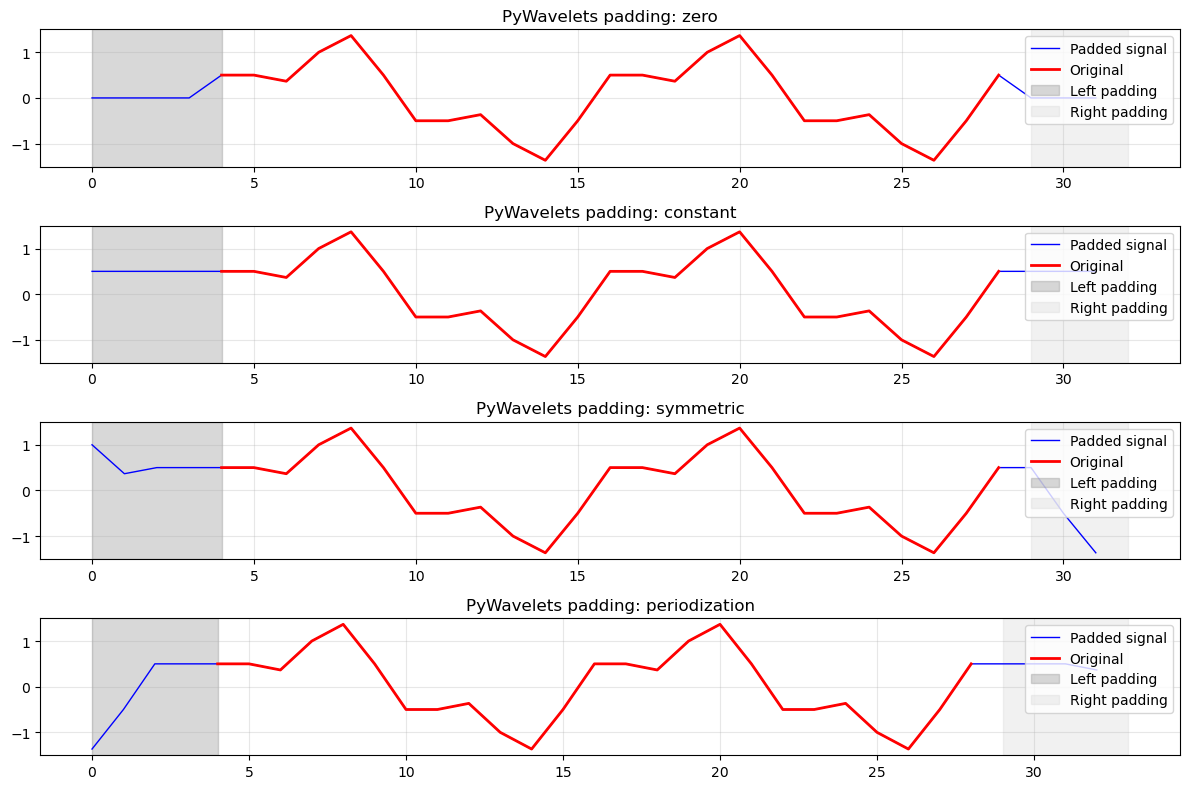

In [ ]:
import numpy as np
import pywt
import matplotlib.pyplot as plt

# Create a test signal with distinct features
t = np.linspace(0, 4*np.pi, 25)
original_signal = np.sin(t) + 0.5*np.cos(3*t)

# Padding parameters
pad_left, pad_right = 4, 3
pad_widths = (pad_left, pad_right)

# Test different PyWavelets padding modes
pywt_modes = ['zero', 'constant', 'symmetric', 'periodization']
padded_signals = {}

for mode in pywt_modes:
    try:
        padded = pywt.pad(original_signal, pad_widths, mode=mode)
        padded_signals[mode] = padded
        print(f"{mode:>15}: length {len(padded)}")
    except Exception as e:
        print(f"{mode:>15}: Error - {e}")

# Visualize the results
fig, axes = plt.subplots(len(padded_signals), 1, figsize=(12, 8))
if len(padded_signals) == 1:
    axes = [axes]

for i, (mode, padded) in enumerate(padded_signals.items()):
    ax = axes[i]
    
    # Plot padded signal
    ax.plot(padded, 'b-', linewidth=1, label='Padded signal')
    
    # Highlight original signal region
    start_idx = pad_left
    end_idx = pad_left + len(original_signal)
    ax.plot(range(start_idx, end_idx), original_signal, 'r-', linewidth=2, label='Original')
    
    # Mark padding regions
    ax.axvspan(0, pad_left, alpha=0.3, color='gray', label='Left padding')
    ax.axvspan(end_idx, len(padded), alpha=0.3, color='lightgray', label='Right padding')
    
    ax.set_title(f'PyWavelets padding: {mode}')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('./output/padding_comparison.png', dpi=300)
plt.show()

**5. Function for Signal Padding**

In [27]:
def prepare_signal_for_swt(signal, target_levels=None):
    signal = np.asarray(signal)
    original_length = len(signal)

    # Step 1: Compute target length (next power of 2)
    target_length = 2 ** int(math.ceil(math.log2(original_length)))

    # Step 2: Calculate padding
    pad_needed = target_length - original_length
    pad_left = pad_needed // 2
    pad_right = pad_needed - pad_left

    # Step 3: Apply padding
    if pad_needed > 0:
        padded_signal = pywt.pad(signal, (pad_left, pad_right), mode='symmetric')
    else:
        padded_signal = signal.copy()

    # Step 4: Determine effective decomposition levels
    max_possible_levels = pywt.swt_max_level(len(padded_signal))
    if target_levels is None:
        effective_levels = max_possible_levels
    else:
        effective_levels = min(target_levels, max_possible_levels)

    pad_info = {
        'original_length': original_length,
        'padded_length': len(padded_signal),
        'pad_left': pad_left,
        'pad_right': pad_right,
        'effective_levels': effective_levels
    }

    return padded_signal, pad_info


# Example usage
np.random.seed(42)
test_signal = np.random.randn(17)  # Non-power-of-2 length

print("=== Preparing Signal for SWT ===")
padded_signal, info = prepare_signal_for_swt(test_signal)

print(f"\nPadding Summary:")
print(f"  Original length: {info['original_length']}")
print(f"  Padded length: {info['padded_length']}")
print(f"  Left padding: {info['pad_left']}")
print(f"  Right padding: {info['pad_right']}")
print(f"  Max levels: {info['effective_levels']}")

# Verify SWT works
try:
    coeffs = pywt.swt(padded_signal, 'db4', level=info['effective_levels'])
    print(f"\nSWT successful! Generated {len(coeffs)} levels of coefficients.")
except Exception as e:
    print(f"\nSWT failed: {e}")

=== Preparing Signal for SWT ===

Padding Summary:
  Original length: 17
  Padded length: 32
  Left padding: 7
  Right padding: 8
  Max levels: 5

SWT successful! Generated 5 levels of coefficients.


## 7.5.5 1D SWT Reconstruction

**1. Full Reconstruction** 

**(b) Example: Complete SWT Decomposition and Reconstruction Example**

In [3]:
import numpy as np
import pywt
import matplotlib.pyplot as plt

# Create a complex test signal
np.random.seed(42)
t = np.linspace(0, 1, num=1024)
clean_signal = (np.sin(2 * np.pi * 10 * t) + 
                0.5 * np.sin(2 * np.pi * 20 * t) + 
                0.3 * np.sin(2 * np.pi * 50 * t))
noise = np.random.normal(0, 0.1, len(t))
noisy_signal = clean_signal + noise

print("=== SWT Decomposition and Reconstruction ===")
print(f"Signal length: {len(noisy_signal)}")

# SWT decomposition
wavelet_name = 'db6'
num_levels = 4
coeffs = pywt.swt(noisy_signal, wavelet_name, level=num_levels)

print(f"Decomposition levels: {len(coeffs)}")
print(f"Coefficient lengths: {[len(c[0]) for c in coeffs]}")

# Full reconstruction
reconstructed_signal = pywt.iswt(coeffs, wavelet_name)

# Verify perfect reconstruction
reconstruction_error = np.max(np.abs(reconstructed_signal - noisy_signal))
print(f"Perfect reconstruction error: {reconstruction_error:.2e}")

# Extract individual level coefficients for analysis
coeff_names = []
approximations = []
details = []

for i, (cA, cD) in enumerate(coeffs[::-1], 1):  # Reverse for intuitive level numbering
    coeff_names.append(f"Level {i}")
    approximations.append(cA)
    details.append(cD)
    print(f"Level {i} - Approx energy: {np.sum(cA**2):.2f}, Detail energy: {np.sum(cD**2):.2f}")

=== SWT Decomposition and Reconstruction ===
Signal length: 1024
Decomposition levels: 4
Coefficient lengths: [1024, 1024, 1024, 1024]
Perfect reconstruction error: 8.88e-16
Level 1 - Approx energy: 1369.79, Detail energy: 9.95
Level 2 - Approx energy: 2729.81, Detail energy: 9.76
Level 3 - Approx energy: 5402.48, Detail energy: 57.15
Level 4 - Approx energy: 10063.29, Detail energy: 741.67


**2. Advanced Partial Reconstruction**

**(a) Define a Function**

In [5]:
def partial_reconstruction_analysis(coeffs, wavelet, signal_length):
    """
    Perform comprehensive partial reconstruction analysis.
    
    Parameters:
    -----------
    coeffs : list
        SWT coefficients [(cA_n, cD_n), ...]
    wavelet : str
        Wavelet used for decomposition
    signal_length : int
        Original signal length for reference
    
    Returns:
    --------
    dict : Dictionary containing all partial reconstructions and analysis
    """
    n_levels = len(coeffs)
    results = {
        'full_reconstruction': None,
        'approximation_only': {},
        'detail_only': {},
        'progressive_reconstruction': {},
        'energy_analysis': {}
    }
    
    # Full reconstruction
    full_recon = pywt.iswt(coeffs, wavelet)
    results['full_reconstruction'] = full_recon
    
    print("=== Partial Reconstruction Analysis ===")
    
    # Create zero templates for selective reconstruction
    zero_coeffs = [(np.zeros_like(cA), np.zeros_like(cD)) for cA, cD in coeffs]
    
    # 1. Approximation-only reconstructions
    print("\n1. Approximation-only reconstructions:")
    for i, (cA, cD) in enumerate(coeffs):
        level = n_levels - i  # Convert to intuitive level numbering
        
        # Create coeffs with only this approximation
        approx_only_coeffs = [(cA.copy(), cD.copy()) for (cA, cD) in zero_coeffs]
        approx_only_coeffs[i] = (cA.copy(), np.zeros_like(cD))
        
        recon_approx = pywt.iswt(approx_only_coeffs, wavelet)
        results['approximation_only'][f'A{level}'] = recon_approx
        
        energy = np.sum(recon_approx**2)
        print(f"  A{level}: Energy = {energy:.2f}")
    
    # 2. Detail-only reconstructions
    print("\n2. Detail-only reconstructions:")
    for i, (cA, cD) in enumerate(coeffs):
        level = n_levels - i
        
        # Create coeffs with only this detail
        detail_only_coeffs = [(cA.copy(), cD.copy()) for (cA, cD) in zero_coeffs]
        detail_only_coeffs[i] = (np.zeros_like(cA), cD.copy())

        
        recon_detail = pywt.iswt(detail_only_coeffs, wavelet)
        results['detail_only'][f'D{level}'] = recon_detail
        
        energy = np.sum(recon_detail**2)
        print(f"  D{level}: Energy = {energy:.2f}")
    
    # 3. Progressive reconstruction (accumulating levels)
    print("\n3. Progressive reconstruction:") 
    progressive_coeffs = [(cA.copy(), cD.copy()) for (cA, cD) in zero_coeffs]

    
    for i, (cA, cD) in enumerate(coeffs):
        level = n_levels - i
        
        # Add this level to progressive reconstruction
        progressive_coeffs[i] = (cA.copy(), cD.copy())
        
        recon_progressive = pywt.iswt(progressive_coeffs, wavelet)
        results['progressive_reconstruction'][f'Up_to_L{level}'] = recon_progressive
        
        # Compare with original
        if i == len(coeffs) - 1:  # Last level should be perfect
            error = np.max(np.abs(recon_progressive - full_recon))
            print(f"  Up to L{level}: Perfect reconstruction error = {error:.2e}")
        else:
            energy_ratio = np.sum(recon_progressive**2) / np.sum(full_recon**2)
            print(f"  Up to L{level}: Energy ratio = {energy_ratio:.3f}")
    
    # 4. Energy analysis
    total_energy = np.sum(full_recon**2)
    results['energy_analysis']['total'] = total_energy
    
    approx_energies = []
    detail_energies = []
    
    for i, (cA, cD) in enumerate(coeffs):
        level = n_levels - i
        approx_energy = np.sum(cA**2)
        detail_energy = np.sum(cD**2)
        
        approx_energies.append(approx_energy)
        detail_energies.append(detail_energy)
        
        results['energy_analysis'][f'A{level}'] = approx_energy
        results['energy_analysis'][f'D{level}'] = detail_energy
    
    print(f"\n4. Energy distribution:")
    print(f"  Total signal energy: {total_energy:.2f}")
    print(f"  Approximation energies: {approx_energies}")
    print(f"  Detail energies: {detail_energies}")
    print(f"  Energy conservation: {(sum(approx_energies) + sum(detail_energies))/total_energy:.6f}")
    
    return results

# Apply partial reconstruction analysis
partial_results = partial_reconstruction_analysis(coeffs, wavelet_name, len(noisy_signal))

=== Partial Reconstruction Analysis ===

1. Approximation-only reconstructions:
  A4: Energy = 626.38
  A3: Energy = 0.00
  A2: Energy = 0.00
  A1: Energy = 0.00

2. Detail-only reconstructions:
  D4: Energy = 38.50
  D3: Energy = 1.61
  D2: Energy = 1.71
  D1: Energy = 4.50

3. Progressive reconstruction:
  Up to L4: Energy ratio = 0.971
  Up to L3: Energy ratio = 0.989
  Up to L2: Energy ratio = 0.992
  Up to L1: Perfect reconstruction error = 0.00e+00

4. Energy distribution:
  Total signal energy: 689.87
  Approximation energies: [np.float64(10063.288214164433), np.float64(5402.477300514614), np.float64(2729.8137922414226), np.float64(1369.7878823115152)]
  Detail energies: [np.float64(741.6663868647943), np.float64(57.15028396823202), np.float64(9.761972381606881), np.float64(9.951389529314524)]
  Energy conservation: 29.547463


**(b) Comprehensive Visualization**

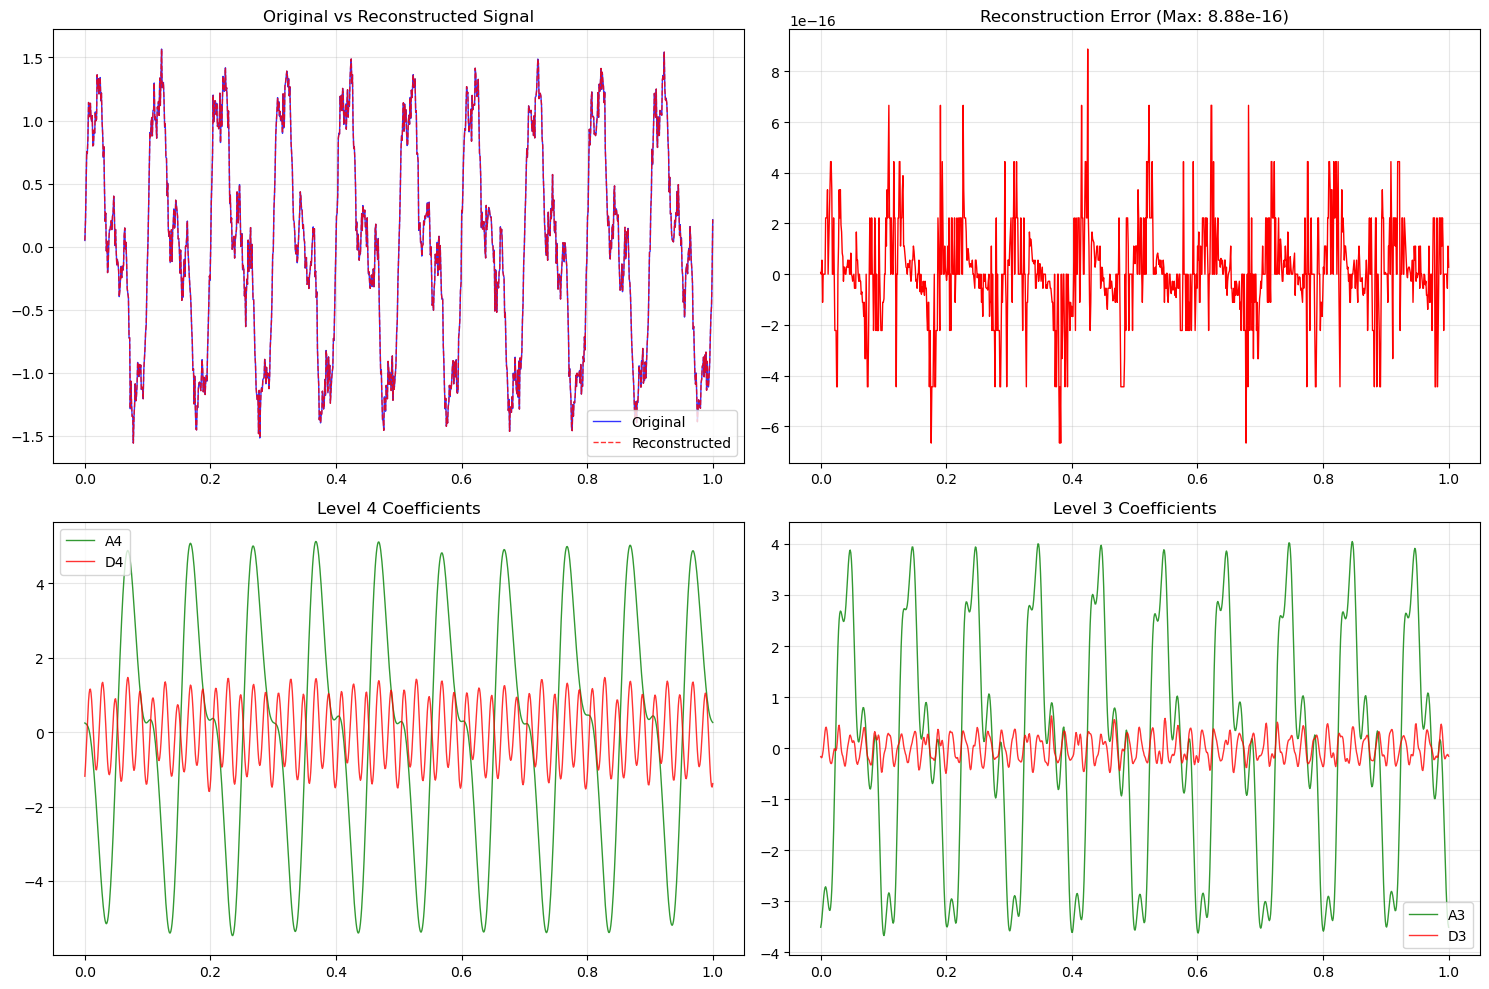

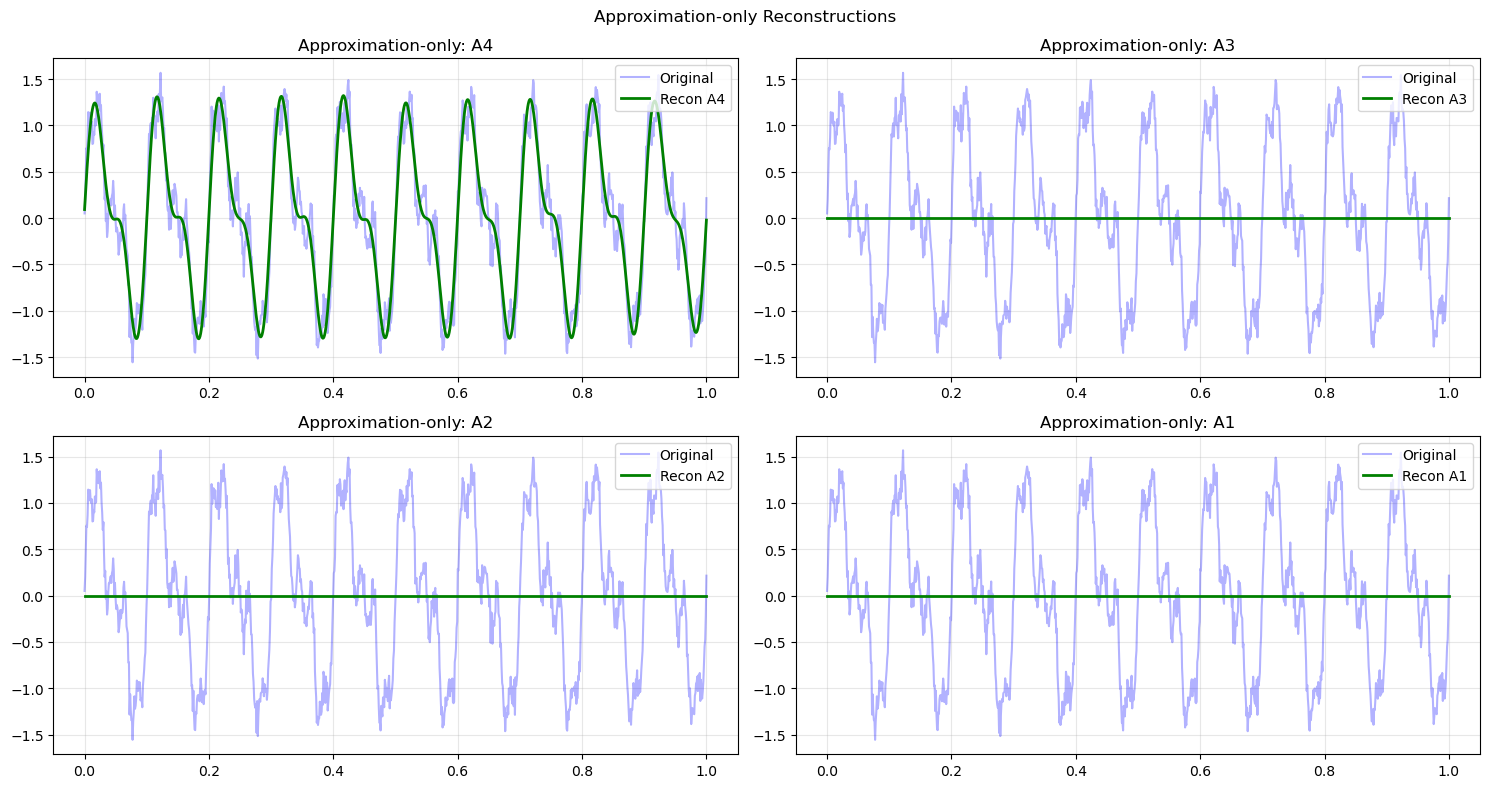

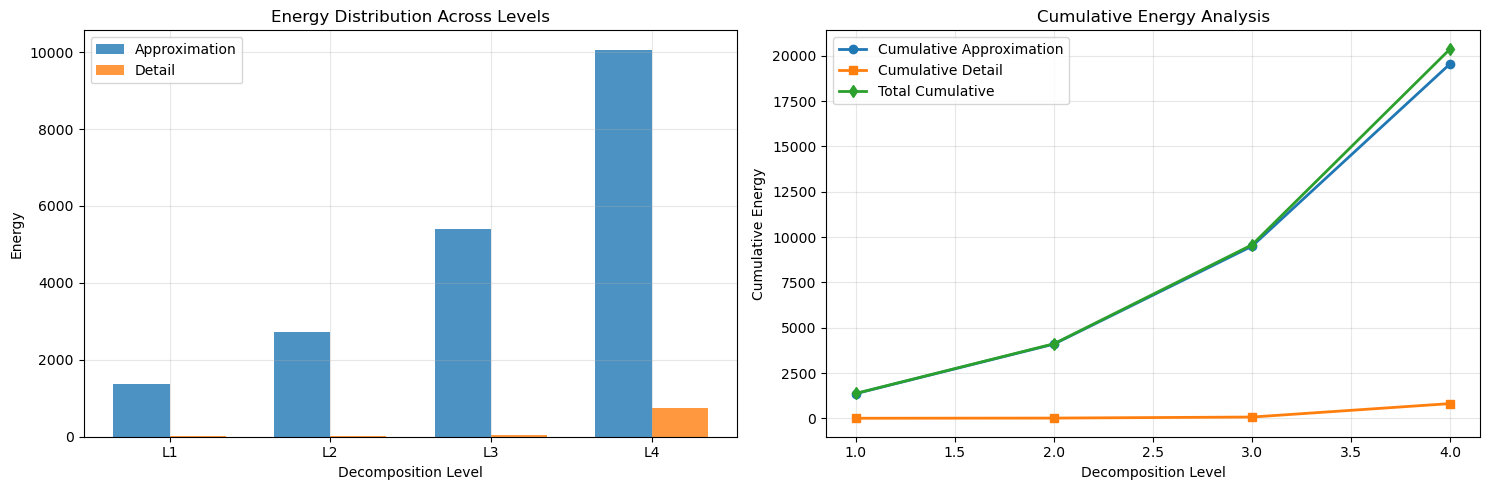

In [9]:
def visualize_swt_analysis(original_signal, coeffs, partial_results, wavelet, t=None):
    """
    Create comprehensive visualization of SWT analysis results.
    """
    if t is None:
        t = np.arange(len(original_signal))
    
    n_levels = len(coeffs)
    
    # Figure 1: Original signal and full reconstruction
    fig1, axes1 = plt.subplots(2, 2, figsize=(15, 10))
    
    # Original and reconstructed signals
    axes1[0,0].plot(t, original_signal, 'b-', linewidth=1, label='Original', alpha=0.8)
    axes1[0,0].plot(t, partial_results['full_reconstruction'], 'r--', 
                   linewidth=1, label='Reconstructed', alpha=0.8)
    axes1[0,0].set_title('Original vs Reconstructed Signal')
    axes1[0,0].legend()
    axes1[0,0].grid(True, alpha=0.3)
    
    # Reconstruction error
    error = original_signal - partial_results['full_reconstruction']
    axes1[0,1].plot(t, error, 'r-', linewidth=1)
    axes1[0,1].set_title(f'Reconstruction Error (Max: {np.max(np.abs(error)):.2e})')
    axes1[0,1].grid(True, alpha=0.3)
    
    # Coefficients at different levels
    for i, (cA, cD) in enumerate(coeffs[:2]):  # Show first 2 levels
        level = n_levels - i
        ax = axes1[1, i] if i < 2 else None
        if ax is not None:
            ax.plot(t, cA, 'g-', label=f'A{level}', alpha=0.8, linewidth=1)
            ax.plot(t, cD, 'r-', label=f'D{level}', alpha=0.8, linewidth=1)
            ax.set_title(f'Level {level} Coefficients')
            ax.legend()
            ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('./output/7.5.1_swt_analysis_overview.png', dpi=300)
    plt.show()
    
    # Figure 2: Partial reconstructions - Approximations only
    fig2, axes2 = plt.subplots(2, 2, figsize=(15, 8))
    axes2 = axes2.flatten()
    
    for i, (key, recon) in enumerate(partial_results['approximation_only'].items()):
        if i < 4:  # Show up to 4 approximations
            axes2[i].plot(t, original_signal, 'b-', alpha=0.3, label='Original')
            axes2[i].plot(t, recon, 'g-', linewidth=2, label=f'Recon {key}')
            axes2[i].set_title(f'Approximation-only: {key}')
            axes2[i].legend()
            axes2[i].grid(True, alpha=0.3)
    
    plt.suptitle('Approximation-only Reconstructions')
    plt.tight_layout()
    plt.savefig('./output/7.5.2_approximation_only.png', dpi=300)
    plt.show()

      # Figure 4: Energy analysis
    fig4, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    
    # Energy distribution
    levels = list(range(1, n_levels + 1))
    approx_energies = [partial_results['energy_analysis'][f'A{i}'] for i in levels]
    detail_energies = [partial_results['energy_analysis'][f'D{i}'] for i in levels]
    
    x = np.arange(len(levels))
    width = 0.35
    
    ax1.bar(x - width/2, approx_energies, width, label='Approximation', alpha=0.8)
    ax1.bar(x + width/2, detail_energies, width, label='Detail', alpha=0.8)
    ax1.set_xlabel('Decomposition Level')
    ax1.set_ylabel('Energy')
    ax1.set_title('Energy Distribution Across Levels')
    ax1.set_xticks(x)
    ax1.set_xticklabels([f'L{i}' for i in levels])
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # Cumulative energy
    cumulative_approx = np.cumsum(approx_energies)
    cumulative_detail = np.cumsum(detail_energies)
    total_cumulative = cumulative_approx + cumulative_detail
    
    ax2.plot(levels, cumulative_approx, 'o-', label='Cumulative Approximation', linewidth=2)
    ax2.plot(levels, cumulative_detail, 's-', label='Cumulative Detail', linewidth=2)
    ax2.plot(levels, total_cumulative, 'd-', label='Total Cumulative', linewidth=2)
    ax2.set_xlabel('Decomposition Level')
    ax2.set_ylabel('Cumulative Energy')
    ax2.set_title('Cumulative Energy Analysis')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('./output/7.5.3_energy_analysis.png', dpi=300)
    plt.show()

# Create a complex test signal
np.random.seed(42)
t = np.linspace(0, 1, num=1024)
clean_signal = (np.sin(2 * np.pi * 10 * t) + 
                0.5 * np.sin(2 * np.pi * 20 * t) + 
                0.3 * np.sin(2 * np.pi * 50 * t))
noise = np.random.normal(0, 0.1, len(t))
noisy_signal = clean_signal + noise

# Apply comprehensive visualization
visualize_swt_analysis(noisy_signal, coeffs, partial_results, wavelet_name, t)

**(c) Practical Denoising Example with Partial Reconstruction**

=== SWT Denoising Demo ===
Signal length: 256
Noise level (std): 0.15

SNR Analysis:
  Original (noisy): 14.78 dB
  Denoised method 1: 0.40 dB
  Denoised method 2: 10.86 dB
  Denoised method 3: 18.18 dB


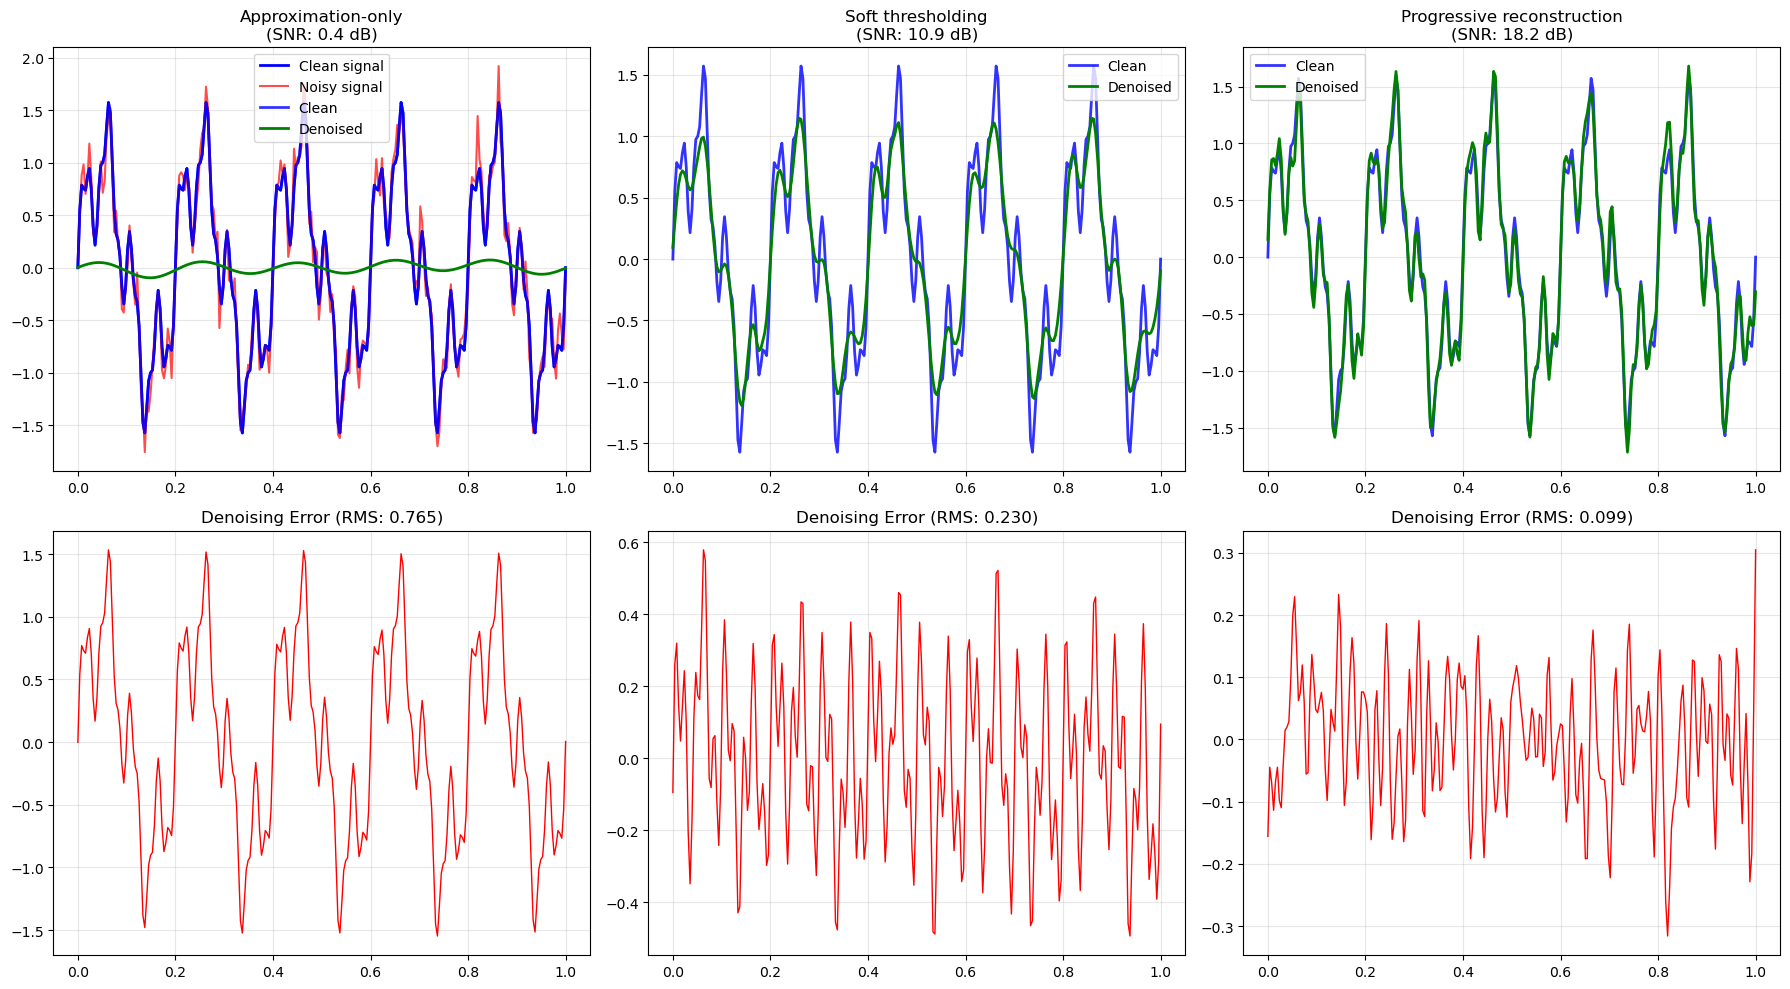

In [10]:
def swt_denoising_demo(signal, noise_level=0.1, wavelet='db6', levels=4):
    """
    Demonstrate SWT-based denoising using partial reconstruction.
    """
    # Add noise to clean signal
    np.random.seed(42)
    noise = np.random.normal(0, noise_level, len(signal))
    noisy_signal = signal + noise
    
    print("=== SWT Denoising Demo ===")
    print(f"Signal length: {len(signal)}")
    print(f"Noise level (std): {noise_level}")
    
    # SWT decomposition of noisy signal
    coeffs = pywt.swt(noisy_signal, wavelet, level=levels)
    
    # Denoising strategy 1: Keep only low-frequency approximations
    denoised_1 = pywt.iswt([(coeffs[0][0], np.zeros_like(coeffs[0][1]))] + 
                          [(np.zeros_like(cA), np.zeros_like(cD)) for cA, cD in coeffs[1:]], wavelet)
    
    # Denoising strategy 2: Soft thresholding of detail coefficients
    threshold = noise_level * np.sqrt(2 * np.log(len(signal)))  # Universal threshold
    coeffs_thresholded = []
    
    for i, (cA, cD) in enumerate(coeffs):
        if i == 0:  # Keep highest level approximation unchanged
            coeffs_thresholded.append((cA, pywt.threshold(cD, threshold, mode='soft')))
        else:  # Threshold detail coefficients
            coeffs_thresholded.append((cA, pywt.threshold(cD, threshold, mode='soft')))
    
    denoised_2 = pywt.iswt(coeffs_thresholded, wavelet)
    
    # Denoising strategy 3: Progressive reconstruction (exclude highest frequency details)
    coeffs_progressive = coeffs[:-1]  # Remove highest frequency details
    if len(coeffs_progressive) > 0:
        denoised_3 = pywt.iswt(coeffs_progressive + 
                              [(np.zeros_like(coeffs[-1][0]), np.zeros_like(coeffs[-1][1]))], wavelet)
    else:
        denoised_3 = denoised_1.copy()
    
    # Calculate performance metrics
    def calculate_snr(clean, noisy):
        signal_power = np.mean(clean**2)
        noise_power = np.mean((clean - noisy)**2)
        return 10 * np.log10(signal_power / noise_power) if noise_power > 0 else float('inf')
    
    original_snr = calculate_snr(signal, noisy_signal)
    denoised_snr_1 = calculate_snr(signal, denoised_1)
    denoised_snr_2 = calculate_snr(signal, denoised_2)
    denoised_snr_3 = calculate_snr(signal, denoised_3)
    
    print(f"\nSNR Analysis:")
    print(f"  Original (noisy): {original_snr:.2f} dB")
    print(f"  Denoised method 1: {denoised_snr_1:.2f} dB")
    print(f"  Denoised method 2: {denoised_snr_2:.2f} dB")
    print(f"  Denoised method 3: {denoised_snr_3:.2f} dB")
    
    # Visualization
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    
    t = np.linspace(0, 1, len(signal))
    
    # Top row: signals
    axes[0,0].plot(t, signal, 'b-', linewidth=2, label='Clean signal')
    axes[0,0].plot(t, noisy_signal, 'r-', alpha=0.7, label='Noisy signal')
    axes[0,0].set_title(f'Original vs Noisy (SNR: {original_snr:.1f} dB)')
    axes[0,0].legend()
    axes[0,0].grid(True, alpha=0.3)
    
    # Denoising results
    methods = [
        (denoised_1, denoised_snr_1, 'Approximation-only'),
        (denoised_2, denoised_snr_2, 'Soft thresholding'),
        (denoised_3, denoised_snr_3, 'Progressive reconstruction')
    ]
    
    for i, (denoised, snr, method_name) in enumerate(methods):
        axes[0, i].plot(t, signal, 'b-', linewidth=2, label='Clean', alpha=0.8)
        axes[0, i].plot(t, denoised, 'g-', linewidth=2, label='Denoised')
        axes[0, i].set_title(f'{method_name}\n(SNR: {snr:.1f} dB)')
        axes[0, i].legend()
        axes[0, i].grid(True, alpha=0.3)
        
        # Bottom row: error analysis
        error = signal - denoised
        axes[1, i].plot(t, error, 'r-', linewidth=1)
        axes[1, i].set_title(f'Denoising Error (RMS: {np.sqrt(np.mean(error**2)):.3f})')
        axes[1, i].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('./output/7.6_swt_denoising_demo.png', dpi=300)
    plt.show()
    
    return {
        'clean': signal,
        'noisy': noisy_signal,
        'denoised_methods': methods,
        'coefficients': coeffs,
        'thresholded_coefficients': coeffs_thresholded
    }

# Demo with synthetic signal
t_demo = np.linspace(0, 1, 256)
clean_demo = (np.sin(2*np.pi*5*t_demo) + 
              0.5*np.sin(2*np.pi*20*t_demo) + 
              0.2*np.sin(2*np.pi*50*t_demo))

denoising_results = swt_denoising_demo(clean_demo, noise_level=0.15, wavelet='db8', levels=5)

### 7.5.6 Practical 1D Multilevel SWT Workflow 
**1. 1D Workfolow with Padding**

In [11]:
def prepare_signal_for_swt(signal, target_levels=None):
    signal = np.asarray(signal)
    original_length = len(signal)

    # Step 1: Compute target length (next power of 2)
    target_length = 2 ** int(math.ceil(math.log2(original_length)))

    # Step 2: Calculate padding
    pad_needed = target_length - original_length
    pad_left = pad_needed // 2
    pad_right = pad_needed - pad_left

    # Step 3: Apply padding
    if pad_needed > 0:
        padded_signal = pywt.pad(signal, (pad_left, pad_right), mode='symmetric')
    else:
        padded_signal = signal.copy()

    # Step 4: Determine effective decomposition levels
    max_possible_levels = pywt.swt_max_level(len(padded_signal))
    if target_levels is None:
        effective_levels = max_possible_levels
    else:
        effective_levels = min(target_levels, max_possible_levels)

    pad_info = {
        'original_length': original_length,
        'padded_length': len(padded_signal),
        'pad_left': pad_left,
        'pad_right': pad_right,
        'effective_levels': effective_levels
    }

    return padded_signal, pad_info


def complete_swt_workflow(signal, wavelet='db4', levels=None, padding_mode='periodization'):
    """
    Complete workflow for SWT with automatic padding.
    
    Parameters:
    -----------
    signal : array_like
        Input signal
    wavelet : str
        Wavelet name
    levels : int, optional
        Number of decomposition levels
    padding_mode : str
        Padding mode for signal extension
    
    Returns:
    --------
    dict with results and metadata
    """
    
    # Step 1: Prepare signal
    padded_signal, pad_info = prepare_signal_for_swt(signal, levels)
    
    # Step 2: Perform SWT
    coeffs = pywt.swt(padded_signal, wavelet, level=pad_info['effective_levels'])
    
    # Step 3: Reconstruction to verify
    reconstructed = pywt.iswt(coeffs, wavelet)
    reconstruction_error = np.mean(np.abs(reconstructed - padded_signal))
    
    return {
        'original_signal': signal,
        'padded_signal': padded_signal,
        'coefficients': coeffs,
        'reconstructed': reconstructed,
        'pad_info': pad_info,
        'reconstruction_error': reconstruction_error,
        'wavelet': wavelet
    }

# Example usage
np.random.seed(123)
test_data = np.sin(np.linspace(0, 4*np.pi, 30)) + 0.1*np.random.randn(30)

results = complete_swt_workflow(test_data, wavelet='db6', levels=4)

print("=== SWT Workflow Results ===")
print(f"Original length: {len(results['original_signal'])}")
print(f"Padded length: {len(results['padded_signal'])}")
print(f"Number of coefficient levels: {len(results['coefficients'])}")
print(f"Reconstruction error: {results['reconstruction_error']:.2e}")
print(f"Wavelet used: {results['wavelet']}")

=== SWT Workflow Results ===
Original length: 30
Padded length: 32
Number of coefficient levels: 4
Reconstruction error: 1.08e-16
Wavelet used: db6


**2. Multilevel Decomposition Practice**

=== Test 1: Noisy Sine Wave ===
=== Enhanced SWT Decomposition ===
Original signal length: 100
Wavelet: db6
Target length: 128
Effective levels: 7
Padding applied: 28 total (14 left, 14 right)
SWT decomposition successful: 7 levels
Level 1: A_energy=154.37, D_energy=11.35
Level 2: A_energy=251.54, D_energy=57.21
Level 3: A_energy=415.57, D_energy=87.51
Level 4: A_energy=20.54, D_energy=810.60
Level 5: A_energy=3.50, D_energy=37.58
Level 6: A_energy=2.11, D_energy=4.89
Level 7: A_energy=0.77, D_energy=3.45
Reconstruction error (original vs reconstructed): 1.04e-16


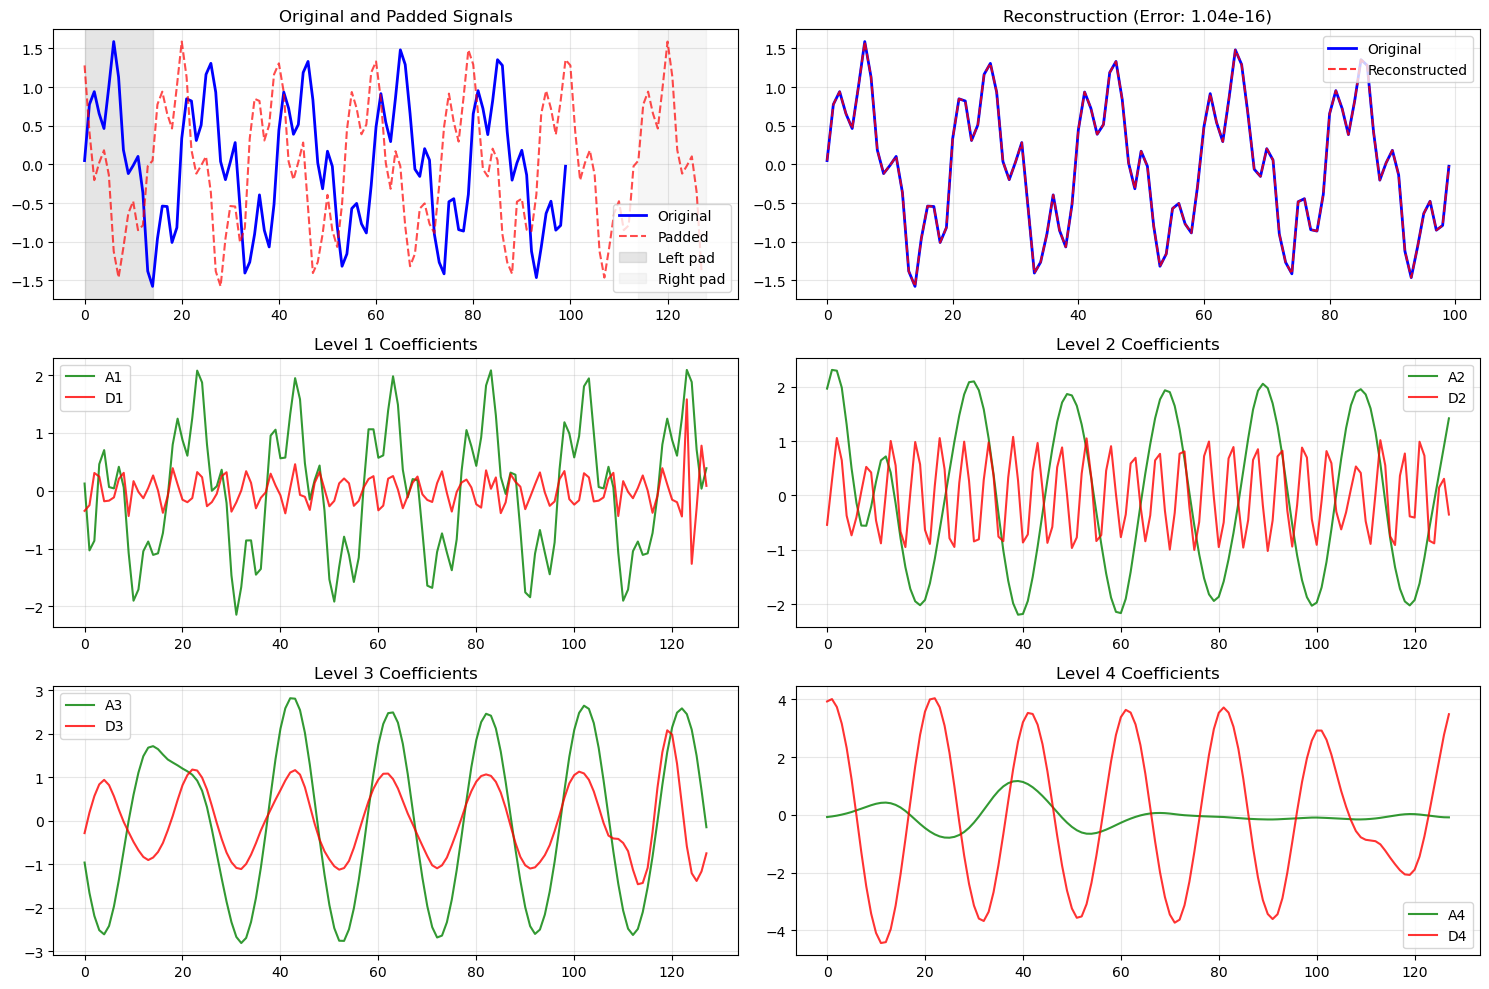

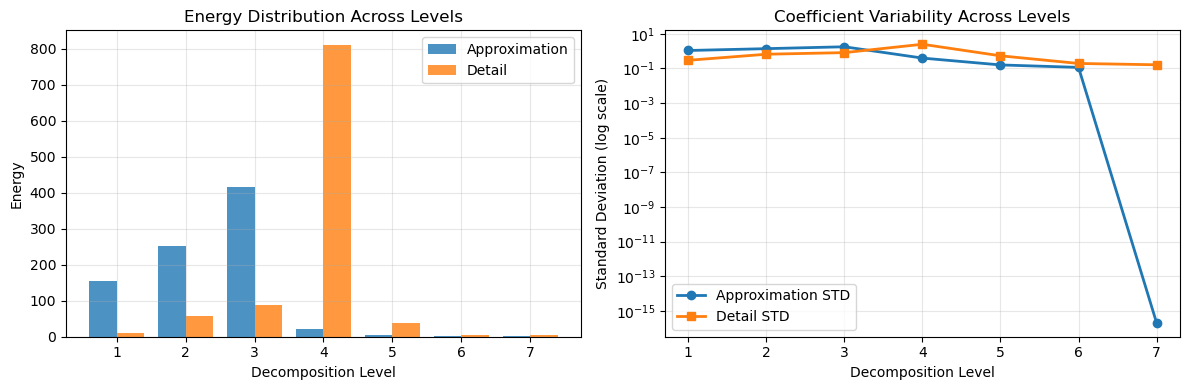


=== Test 2: Step Function ===
=== Enhanced SWT Decomposition ===
Original signal length: 75
Wavelet: haar
Target length: 128
Effective levels: 7
Padding applied: 53 total (26 left, 27 right)
SWT decomposition failed: Length of data must be even.


In [1]:
import numpy as np
import pywt
import matplotlib.pyplot as plt
import math

def enhanced_swt_decomposition(signal, wavelet='db4', levels=None, show_plot=True):
    """
    Enhanced SWT decomposition with comprehensive analysis and visualization.
    
    Parameters:
    -----------
    signal : array_like
        Input signal
    wavelet : str
        Wavelet name (default: 'db4')
    levels : int, optional
        Number of decomposition levels (default: maximum possible)
    show_plot : bool
        Whether to show visualization plots
    
    Returns:
    --------
    dict : Complete decomposition results and analysis
    """
    
    # Convert to numpy array
    signal = np.asarray(signal)
    original_length = len(signal)
    
    print("=== Enhanced SWT Decomposition ===")
    print(f"Original signal length: {original_length}")
    print(f"Wavelet: {wavelet}")
    
    # Step 1: Determine padding requirements
    if levels is None:
        max_possible = pywt.swt_max_level(original_length)
        target_length = 2 ** int(math.ceil(math.log2(original_length)))
        effective_levels = int(math.log2(target_length))
    else:
        target_length = max(2 ** levels, 2 ** int(math.ceil(math.log2(original_length))))
        effective_levels = int(math.log2(target_length))
    
    print(f"Target length: {target_length}")
    print(f"Effective levels: {effective_levels}")
    
    # Step 2: Pad signal if necessary
    pad_needed = target_length - original_length
    if pad_needed > 0:
        pad_left = pad_needed // 2
        pad_right = pad_needed - pad_left
        padded_signal = pywt.pad(signal, (pad_left, pad_right), mode='periodization')
        print(f"Padding applied: {pad_needed} total ({pad_left} left, {pad_right} right)")
    else:
        padded_signal = signal.copy()
        pad_left = pad_right = 0
        print("No padding needed")
    
    # Step 3: Perform SWT decomposition
    try:
        coeffs = pywt.swt(padded_signal, wavelet, level=effective_levels)
        print(f"SWT decomposition successful: {len(coeffs)} levels")
    except Exception as e:
        print(f"SWT decomposition failed: {e}")
        return None
    
    # Step 4: Analyze coefficients
    coeff_stats = []
    total_energy = 0
    
    for i, (cA, cD) in enumerate(coeffs[::-1], 1):  # Reverse for level 1, 2, 3...
        approx_energy = np.sum(cA**2)
        detail_energy = np.sum(cD**2)
        total_energy += approx_energy + detail_energy
        
        stats = {
            'level': i,
            'approx_energy': approx_energy,
            'detail_energy': detail_energy,
            'approx_max': np.max(np.abs(cA)),
            'detail_max': np.max(np.abs(cD)),
            'approx_std': np.std(cA),
            'detail_std': np.std(cD)
        }
        coeff_stats.append(stats)
        
        print(f"Level {i}: A_energy={approx_energy:.2f}, D_energy={detail_energy:.2f}")
    
    # Step 5: Reconstruction verification
    reconstructed = pywt.iswt(coeffs, wavelet)
    
    # Remove padding from reconstruction for comparison
    if pad_needed > 0:
        reconstructed_original = reconstructed[pad_left:pad_left+original_length]
    else:
        reconstructed_original = reconstructed
    
    reconstruction_error = np.mean(np.abs(signal - reconstructed_original))
    print(f"Reconstruction error (original vs reconstructed): {reconstruction_error:.2e}")
    
    # Step 6: Visualization
    if show_plot:
        fig = plt.figure(figsize=(15, 10))
        
        # Plot 1: Original and padded signals
        plt.subplot(3, 2, 1)
        plt.plot(signal, 'b-', linewidth=2, label='Original')
        if pad_needed > 0:
            plt.plot(padded_signal, 'r--', alpha=0.7, label='Padded')
            plt.axvspan(0, pad_left, alpha=0.2, color='gray', label='Left pad')
            plt.axvspan(pad_left+original_length, len(padded_signal), alpha=0.2, color='lightgray', label='Right pad')
        plt.title('Original and Padded Signals')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Plot 2: Reconstruction comparison
        plt.subplot(3, 2, 2)
        plt.plot(signal, 'b-', linewidth=2, label='Original')
        plt.plot(reconstructed_original, 'r--', alpha=0.8, label='Reconstructed')
        plt.title(f'Reconstruction (Error: {reconstruction_error:.2e})')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Plots 3-6: Coefficients at each level
        n_levels = min(4, len(coeffs))
        for i in range(n_levels):
            plt.subplot(3, 2, 3+i)
            cA, cD = coeffs[-(i+1)]  # Start from level 1
            plt.plot(cA, 'g-', label=f'A{i+1}', alpha=0.8)
            plt.plot(cD, 'r-', label=f'D{i+1}', alpha=0.8)
            plt.title(f'Level {i+1} Coefficients')
            plt.legend()
            plt.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.savefig('./output/9.5.1_enhanced_swt_coefficients.png', dpi=300)
        plt.show()
        
        # Energy distribution plot
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
        
        levels = [s['level'] for s in coeff_stats]
        approx_energies = [s['approx_energy'] for s in coeff_stats]
        detail_energies = [s['detail_energy'] for s in coeff_stats]
        
        ax1.bar([l-0.2 for l in levels], approx_energies, 0.4, label='Approximation', alpha=0.8)
        ax1.bar([l+0.2 for l in levels], detail_energies, 0.4, label='Detail', alpha=0.8)
        ax1.set_xlabel('Decomposition Level')
        ax1.set_ylabel('Energy')
        ax1.set_title('Energy Distribution Across Levels')
        ax1.legend()
        ax1.grid(True, alpha=0.3)
        
        # Standard deviation comparison
        approx_stds = [s['approx_std'] for s in coeff_stats]
        detail_stds = [s['detail_std'] for s in coeff_stats]
        
        ax2.semilogy(levels, approx_stds, 'o-', label='Approximation STD', linewidth=2)
        ax2.semilogy(levels, detail_stds, 's-', label='Detail STD', linewidth=2)
        ax2.set_xlabel('Decomposition Level')
        ax2.set_ylabel('Standard Deviation (log scale)')
        ax2.set_title('Coefficient Variability Across Levels')
        ax2.legend()
        ax2.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.savefig('./output/enhanced_swt_analysis.png', dpi=300)
        plt.show()
    
    # Return comprehensive results
    return {
        'original_signal': signal,
        'padded_signal': padded_signal,
        'coefficients': coeffs,
        'reconstructed_full': reconstructed,
        'reconstructed_original': reconstructed_original,
        'coefficient_stats': coeff_stats,
        'metadata': {
            'original_length': original_length,
            'padded_length': len(padded_signal),
            'effective_levels': effective_levels,
            'pad_left': pad_left,
            'pad_right': pad_right,
            'reconstruction_error': reconstruction_error,
            'total_energy': total_energy,
            'wavelet': wavelet
        }
    }

# Example usage with different signal types
if __name__ == "__main__":
    # Test 1: Synthetic noisy sine wave
    print("=== Test 1: Noisy Sine Wave ===")
    np.random.seed(42)
    t = np.linspace(0, 2*np.pi, 100)
    test_signal_1 = np.sin(5*t) + 0.5*np.sin(20*t) + 0.1*np.random.randn(100)
    
    results_1 = enhanced_swt_decomposition(test_signal_1, wavelet='db6', levels=4)
    
    # Test 2: Step function with noise
    print("\n=== Test 2: Step Function ===")
    test_signal_2 = np.concatenate([np.ones(25), -np.ones(30), np.ones(20)])
    test_signal_2 += 0.05 * np.random.randn(len(test_signal_2))
    
    results_2 = enhanced_swt_decomposition(test_signal_2, wavelet='haar', levels=3)

## 7.6 2D Stationary Wavelet Transform
**3. Example: Comprehensive demonstration of 2D SWT**

=== 2D Stationary Wavelet Transform Demo ===

Processing camera image...
  2D SWT completed: 3 levels
  Each level shape: (512, 512)
  Reconstruction error: 2.27e-13

Processing coins image...
  Padded from (303, 384) to (512, 512)
  2D SWT completed: 3 levels
  Each level shape: (512, 512)
  Reconstruction error: 1.71e-13

Processing checkerboard image...
  Padded from (200, 200) to (256, 256)
  2D SWT completed: 3 levels
  Each level shape: (256, 256)
  Reconstruction error: 2.27e-13


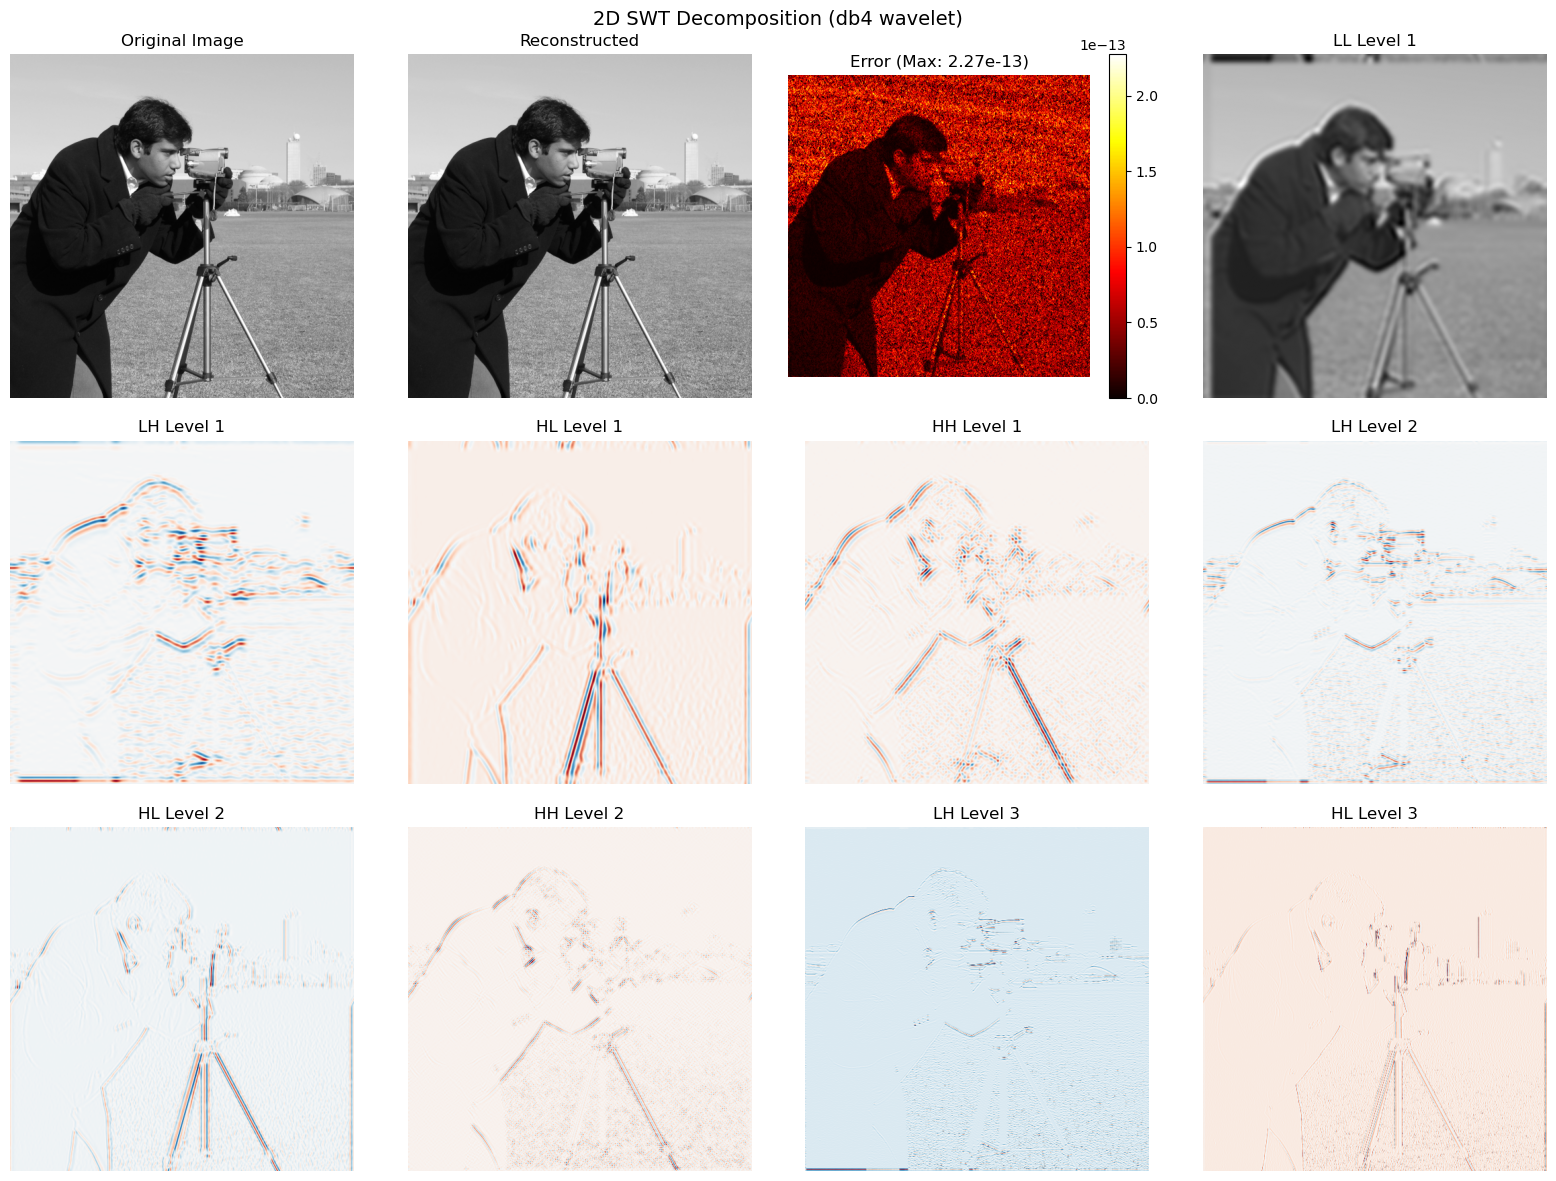

=== 2D SWT Denoising Demo ===
Original image shape: (512, 512)
Noise level (std): 0.1
Original PSNR: 20.43 dB
Soft thresholding PSNR: 23.18 dB
Approximation-only PSNR: 21.36 dB


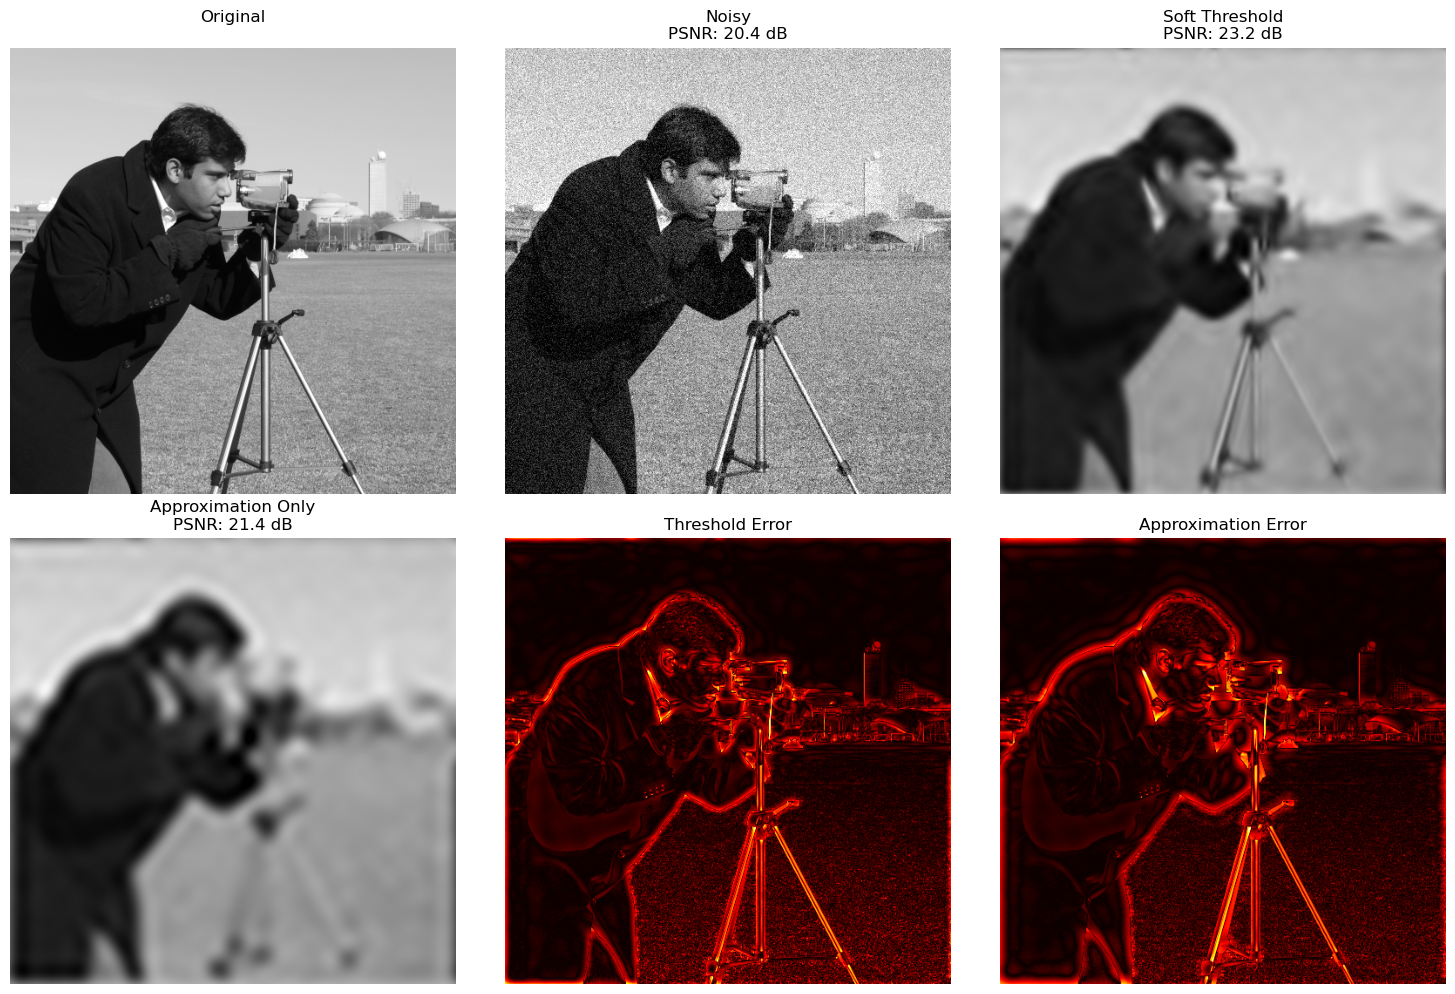

In [ ]:
import numpy as np
import pywt
import matplotlib.pyplot as plt
from skimage import data, metrics
import cv2

def swt2d_comprehensive_demo():
    """
    Comprehensive demonstration of 2D SWT with multiple examples.
    """
    print("=== 2D Stationary Wavelet Transform Demo ===")
    
    # Load test images
    images = {
        'camera': data.camera(),
        'coins': data.coins(),
        'checkerboard': data.checkerboard()
    }
    
    results = {}
    
    for img_name, img in images.items():
        print(f"\nProcessing {img_name} image...")
        
        # Ensure image dimensions are suitable for SWT
        h, w = img.shape
        target_h = 2 ** int(np.ceil(np.log2(h)))
        target_w = 2 ** int(np.ceil(np.log2(w)))
        
        if h != target_h or w != target_w:
            img_padded = np.pad(img, 
                               ((0, target_h - h), (0, target_w - w)), 
                               mode='symmetric')
            print(f"  Padded from {(h,w)} to {img_padded.shape}")
        else:
            img_padded = img.copy()
        
        # Perform 2D SWT
        wavelet = 'db4'
        levels = 3
        coeffs_2d = pywt.swt2(img_padded, wavelet, levels)
        
        print(f"  2D SWT completed: {levels} levels")
        print(f"  Each level shape: {coeffs_2d[0][0].shape}")
        
        # Reconstruction
        reconstructed = pywt.iswt2(coeffs_2d, wavelet)
        reconstruction_error = np.max(np.abs(reconstructed - img_padded))
        print(f"  Reconstruction error: {reconstruction_error:.2e}")
        
        results[img_name] = {
            'original': img,
            'padded': img_padded,
            'coefficients': coeffs_2d,
            'reconstructed': reconstructed,
            'wavelet': wavelet,
            'levels': levels
        }
    
    return results

def visualize_2d_swt(img, coeffs_2d, wavelet, max_levels=3):
    """
    Visualize 2D SWT decomposition results.
    
    Parameters:
    -----------
    img : ndarray
        Original image
    coeffs_2d : list
        2D SWT coefficients
    wavelet : str
        Wavelet used
    max_levels : int
        Maximum levels to display
    """
    n_levels = min(len(coeffs_2d), max_levels)
    
    # Create comprehensive visualization
    fig = plt.figure(figsize=(16, 12))
    
    # Original image
    plt.subplot(3, 4, 1)
    plt.imshow(img, cmap='gray')
    plt.title('Original Image')
    plt.axis('off')
    
    # Reconstructed image
    reconstructed = pywt.iswt2(coeffs_2d, wavelet)
    plt.subplot(3, 4, 2)
    plt.imshow(reconstructed, cmap='gray')
    plt.title('Reconstructed')
    plt.axis('off')
    
    # Error image
    error = np.abs(reconstructed - img)
    plt.subplot(3, 4, 3)
    plt.imshow(error, cmap='hot')
    plt.title(f'Error (Max: {np.max(error):.2e})')
    plt.colorbar()
    plt.axis('off')
    
    # Display coefficients for each level
    plot_idx = 4
    for level in range(n_levels):
        LL, (LH, HL, HH) = coeffs_2d[level]
        
        # Show approximation (LL) for first level
        if level == 0:
            plt.subplot(3, 4, plot_idx)
            plt.imshow(LL, cmap='gray')
            plt.title(f'LL Level {level+1}')
            plt.axis('off')
            plot_idx += 1
        
        # Show detail coefficients
        details = [('LH', LH), ('HL', HL), ('HH', HH)]
        for detail_name, detail_coeff in details:
            if plot_idx <= 12:
                plt.subplot(3, 4, plot_idx)
                plt.imshow(detail_coeff, cmap='RdBu_r')
                plt.title(f'{detail_name} Level {level+1}')
                plt.axis('off')
                plot_idx += 1
    
    plt.suptitle(f'2D SWT Decomposition ({wavelet} wavelet)', fontsize=14)
    plt.tight_layout()
    plt.savefig('./output/7.8_2d_swt_comprehensive.png', dpi=300)   
    plt.show()

def swt2d_denoising_demo():
    """
    Demonstrate 2D SWT for image denoising.
    """
    print("=== 2D SWT Denoising Demo ===")
    
    # Load and prepare test image
    original_img = data.camera()
    original_img = original_img.astype(np.float64) / 255.0
    
    # Add noise
    np.random.seed(42)
    noise_level = 0.1
    noise = np.random.normal(0, noise_level, original_img.shape)
    noisy_img = original_img + noise
    noisy_img = np.clip(noisy_img, 0, 1)
    
    print(f"Original image shape: {original_img.shape}")
    print(f"Noise level (std): {noise_level}")
    
    # Ensure dimensions are powers of 2
    h, w = noisy_img.shape
    target_h = 2 ** int(np.ceil(np.log2(h)))
    target_w = 2 ** int(np.ceil(np.log2(w)))
    
    if h != target_h or w != target_w:
        noisy_padded = np.pad(noisy_img, 
                             ((0, target_h - h), (0, target_w - w)), 
                             mode='symmetric')
        original_padded = np.pad(original_img,
                                ((0, target_h - h), (0, target_w - w)), 
                                mode='symmetric')
    else:
        noisy_padded = noisy_img.copy()
        original_padded = original_img.copy()
    
    # 2D SWT decomposition
    wavelet = 'db6'
    levels = 4
    coeffs = pywt.swt2(noisy_padded, wavelet, levels)
    
    # Denoising methods
    def calculate_psnr(img1, img2):
        mse = np.mean((img1 - img2) ** 2)
        if mse == 0:
            return float('inf')
        return 20 * np.log10(1.0 / np.sqrt(mse))
    
    original_psnr = calculate_psnr(original_padded, noisy_padded)
    print(f"Original PSNR: {original_psnr:.2f} dB")
    
    # Method 1: Soft thresholding
    threshold = noise_level * np.sqrt(2 * np.log(noisy_padded.size))
    coeffs_thresh = []
    
    for level, (LL, (LH, HL, HH)) in enumerate(coeffs):
        if level == 0:  # Keep approximation at finest level
            coeffs_thresh.append((LL, (
                pywt.threshold(LH, threshold, mode='soft'),
                pywt.threshold(HL, threshold, mode='soft'), 
                pywt.threshold(HH, threshold, mode='soft')
            )))
        else:
            coeffs_thresh.append((LL, (
                pywt.threshold(LH, threshold * (2**level), mode='soft'),
                pywt.threshold(HL, threshold * (2**level), mode='soft'),
                pywt.threshold(HH, threshold * (2**level), mode='soft')
            )))
    
    denoised_thresh = pywt.iswt2(coeffs_thresh, wavelet)
    psnr_thresh = calculate_psnr(original_padded, denoised_thresh)
    
    # Method 2: Approximation only (aggressive denoising)
    coeffs_approx = []
    for level, (LL, (LH, HL, HH)) in enumerate(coeffs):
        if level == len(coeffs) - 1:  # Keep only the coarsest approximation
            coeffs_approx.append((LL, (
                np.zeros_like(LH), np.zeros_like(HL), np.zeros_like(HH)
            )))
        else:
            coeffs_approx.append((LL, (
                np.zeros_like(LH), np.zeros_like(HL), np.zeros_like(HH)
            )))
    
    denoised_approx = pywt.iswt2(coeffs_approx, wavelet)
    psnr_approx = calculate_psnr(original_padded, denoised_approx)
    
    print(f"Soft thresholding PSNR: {psnr_thresh:.2f} dB")
    print(f"Approximation-only PSNR: {psnr_approx:.2f} dB")
    
    # Visualization
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    
    # Remove padding for display
    def remove_padding(img, original_shape):
        return img[:original_shape[0], :original_shape[1]]
    
    images_to_show = [
        (remove_padding(original_padded, original_img.shape), 'Original', ''),
        (remove_padding(noisy_padded, original_img.shape), 'Noisy', f'PSNR: {original_psnr:.1f} dB'),
        (remove_padding(denoised_thresh, original_img.shape), 'Soft Threshold', f'PSNR: {psnr_thresh:.1f} dB'),
        (remove_padding(denoised_approx, original_img.shape), 'Approximation Only', f'PSNR: {psnr_approx:.1f} dB'),
    ]
    
    for i, (img, title, subtitle) in enumerate(images_to_show):
        row, col = i // 3, i % 3
        axes[row, col].imshow(img, cmap='gray', vmin=0, vmax=1)
        axes[row, col].set_title(f'{title}\n{subtitle}')
        axes[row, col].axis('off')
    
    # Error images
    error_thresh = np.abs(remove_padding(original_padded, original_img.shape) - 
                         remove_padding(denoised_thresh, original_img.shape))
    error_approx = np.abs(remove_padding(original_padded, original_img.shape) - 
                         remove_padding(denoised_approx, original_img.shape))
    
    axes[1, 1].imshow(error_thresh, cmap='hot')
    axes[1, 1].set_title('Threshold Error')
    axes[1, 1].axis('off')
    
    axes[1, 2].imshow(error_approx, cmap='hot')
    axes[1, 2].set_title('Approximation Error')
    axes[1, 2].axis('off')
    
    plt.tight_layout()
    plt.savefig('./output/7.9_2d_swt_denoising.png', dpi=300)   
    plt.show()
    
    return {
        'original': original_img,
        'noisy': remove_padding(noisy_padded, original_img.shape),
        'denoised_threshold': remove_padding(denoised_thresh, original_img.shape),
        'denoised_approximation': remove_padding(denoised_approx, original_img.shape),
        'psnr_original': original_psnr,
        'psnr_threshold': psnr_thresh,
        'psnr_approximation': psnr_approx
    }

# Run demonstrations
if __name__ == "__main__":
    # 2D SWT basic demo
    demo_results = swt2d_comprehensive_demo()
    
    # Visualize results for one image
    img_name = 'camera'
    if img_name in demo_results:
        visualize_2d_swt(
            demo_results[img_name]['padded'],
            demo_results[img_name]['coefficients'],
            demo_results[img_name]['wavelet']
        )
    
    # 2D SWT denoising demo
    denoising_results = swt2d_denoising_demo()


### 7.6.4 Advanced 2D SWT Applications

=== 2D SWT Texture Analysis ===

Analyzing vertical_stripes...
  Level 1 energy distribution:
    LL: 0.800
    LH: 0.000
    HL: 0.200
    HH: 0.000

Analyzing diagonal_pattern...
  Level 1 energy distribution:
    LL: 0.750
    LH: 0.083
    HL: 0.083
    HH: 0.083

Analyzing structured_noise...
  Level 1 energy distribution:
    LL: 0.970
    LH: 0.010
    HL: 0.011
    HH: 0.009

Analyzing checkerboard...
  Level 1 energy distribution:
    LL: 0.915
    LH: 0.040
    HL: 0.040
    HH: 0.004


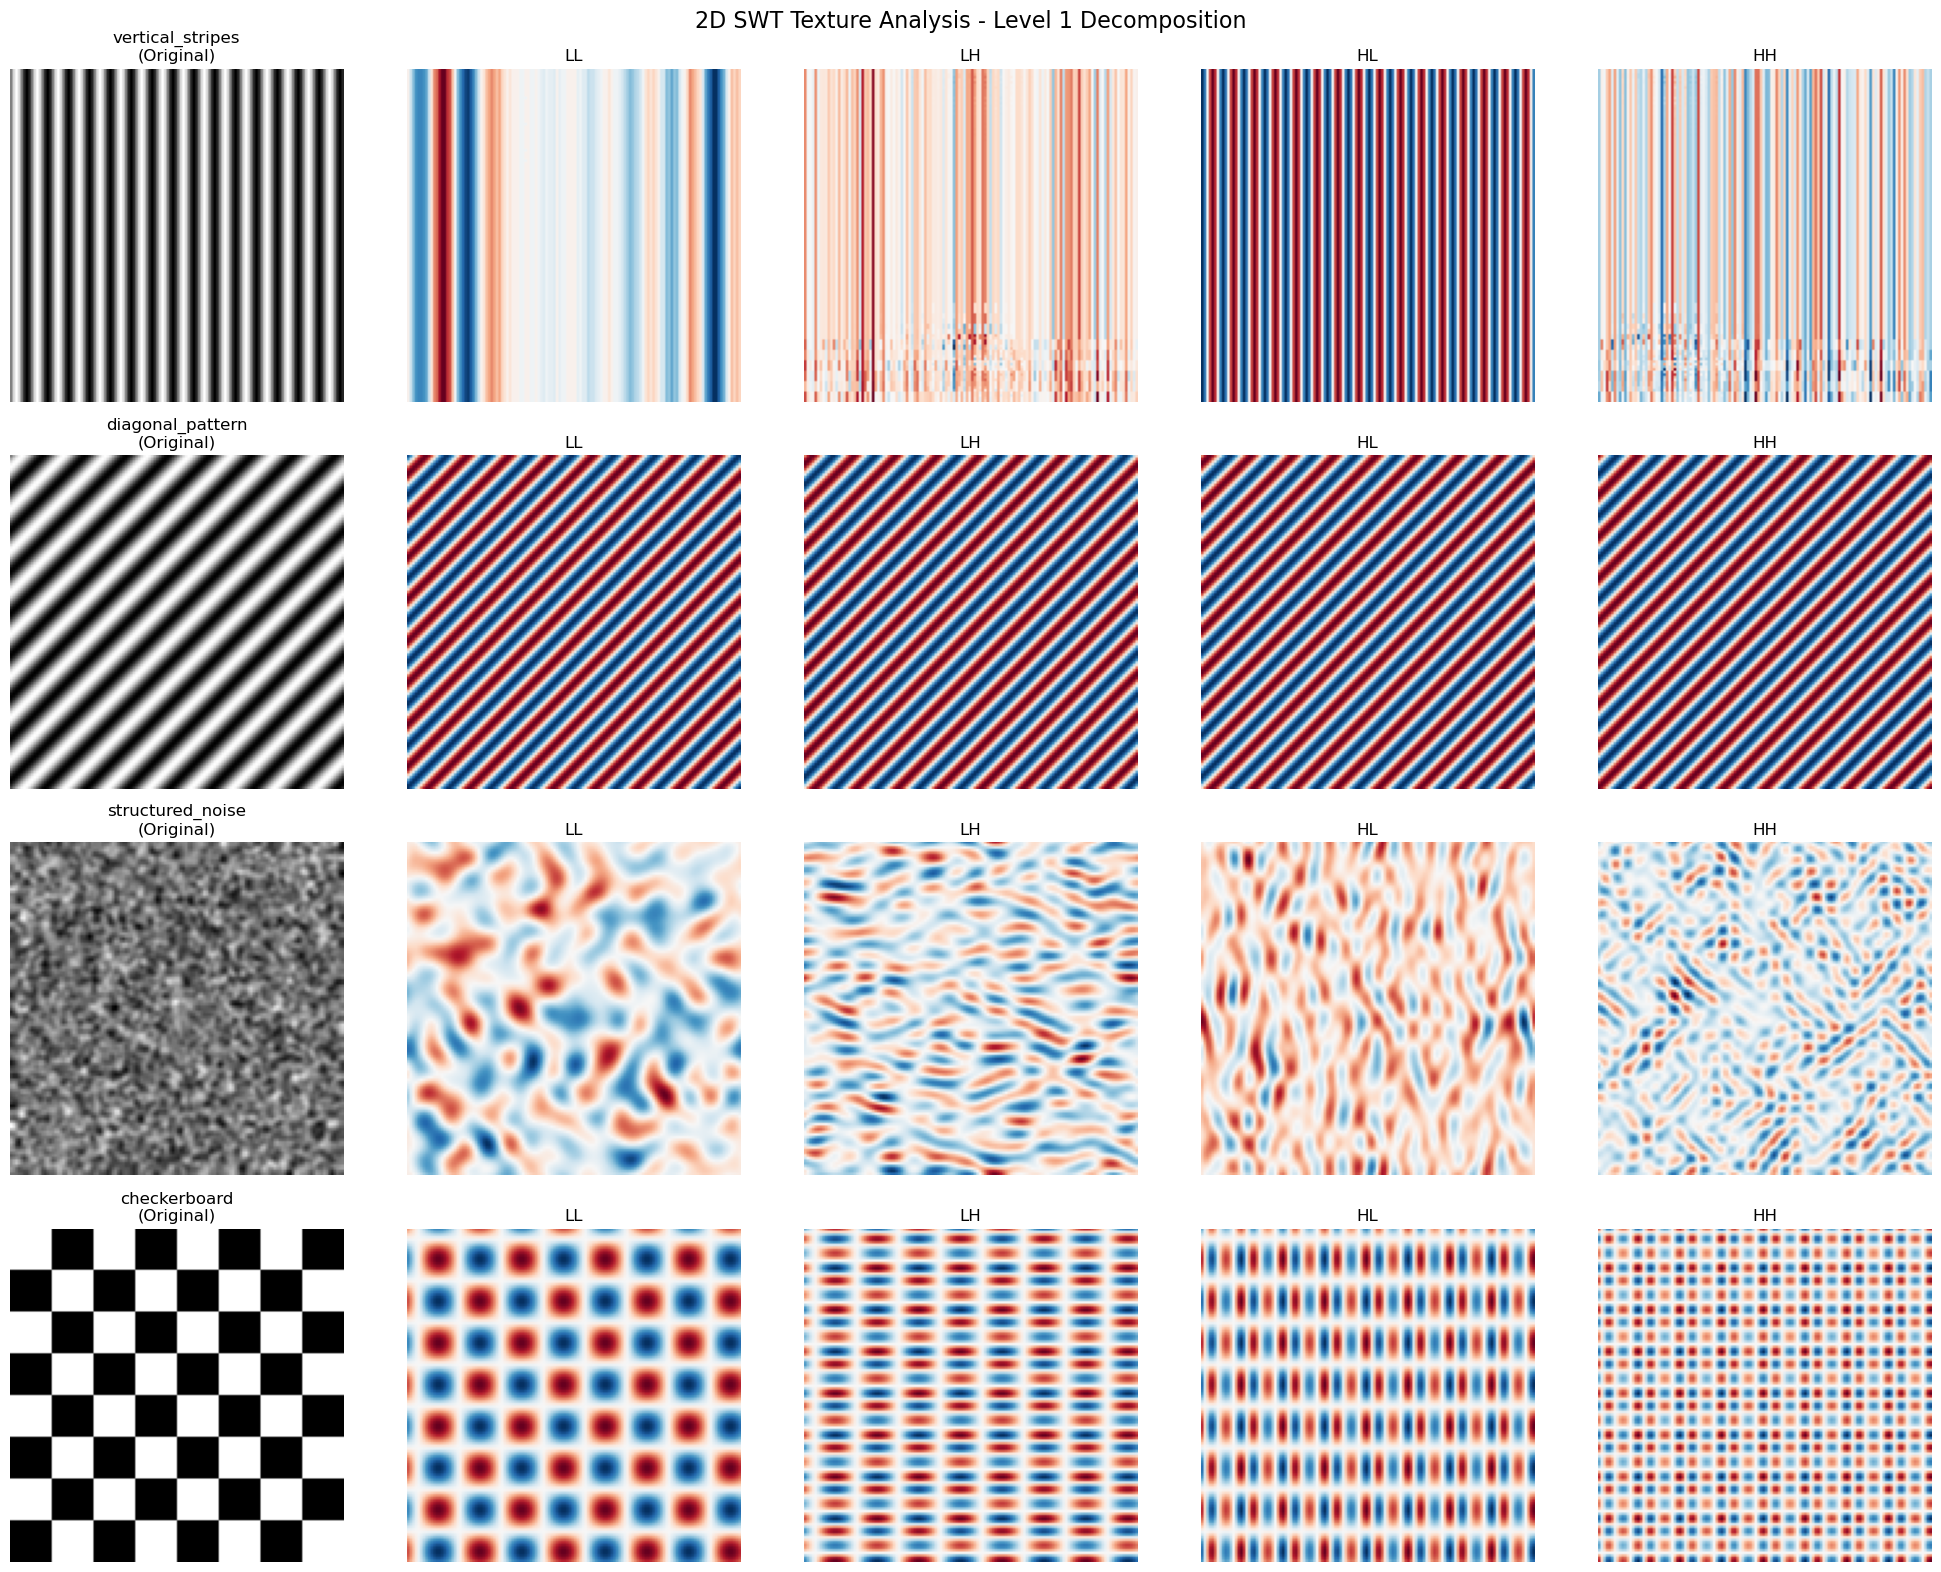

In [ ]:
def swt2d_texture_analysis():
    """
    Demonstrate 2D SWT for texture analysis and feature extraction.
    """
    print("=== 2D SWT Texture Analysis ===")
    
    # Create synthetic textures
    def create_texture_samples():
        np.random.seed(42)
        size = (128, 128)
        
        # Texture 1: Vertical stripes
        x = np.arange(size[1])
        texture1 = np.tile(np.sin(2 * np.pi * x / 8), (size[0], 1))
        
        # Texture 2: Diagonal pattern
        x, y = np.meshgrid(np.arange(size[1]), np.arange(size[0]))
        texture2 = np.sin(2 * np.pi * (x + y) / 16)
        
        # Texture 3: Random noise with structure
        texture3 = np.random.randn(*size)
        texture3 = cv2.GaussianBlur(texture3, (5, 5), 1.0)
        
        # Texture 4: Checkerboard-like
        texture4 = np.zeros(size)
        block_size = 16
        for i in range(0, size[0], block_size):
            for j in range(0, size[1], block_size):
                if ((i // block_size) + (j // block_size)) % 2 == 0:
                    texture4[i:i+block_size, j:j+block_size] = 1
        
        return {
            'vertical_stripes': texture1,
            'diagonal_pattern': texture2,
            'structured_noise': texture3,
            'checkerboard': texture4
        }
    
    textures = create_texture_samples()
    
    # Analyze each texture using 2D SWT
    wavelet = 'db8'
    levels = 3
    
    texture_features = {}
    
    for name, texture in textures.items():
        print(f"\nAnalyzing {name}...")
        
        # Normalize texture
        texture_norm = (texture - np.min(texture)) / (np.max(texture) - np.min(texture))
        
        # 2D SWT decomposition
        coeffs = pywt.swt2(texture_norm, wavelet, levels)
        
        # Extract features from each subband
        features = {}
        
        for level, (LL, (LH, HL, HH)) in enumerate(coeffs):
            level_features = {}
            
            # Energy features
            level_features['LL_energy'] = np.sum(LL**2)
            level_features['LH_energy'] = np.sum(LH**2)
            level_features['HL_energy'] = np.sum(HL**2)  
            level_features['HH_energy'] = np.sum(HH**2)
            
            # Statistical features
            for subband_name, subband in [('LL', LL), ('LH', LH), ('HL', HL), ('HH', HH)]:
                level_features[f'{subband_name}_mean'] = np.mean(subband)
                level_features[f'{subband_name}_std'] = np.std(subband)
                level_features[f'{subband_name}_skew'] = scipy.stats.skew(subband.flatten())
                level_features[f'{subband_name}_kurt'] = scipy.stats.kurtosis(subband.flatten())
            
            features[f'level_{level+1}'] = level_features
        
        texture_features[name] = features
        
        # Print key features
        print(f"  Level 1 energy distribution:")
        l1_features = features['level_1']
        total_energy = (l1_features['LL_energy'] + l1_features['LH_energy'] + 
                       l1_features['HL_energy'] + l1_features['HH_energy'])
        print(f"    LL: {l1_features['LL_energy']/total_energy:.3f}")
        print(f"    LH: {l1_features['LH_energy']/total_energy:.3f}")
        print(f"    HL: {l1_features['HL_energy']/total_energy:.3f}")
        print(f"    HH: {l1_features['HH_energy']/total_energy:.3f}")
    
    # Visualization
    fig, axes = plt.subplots(4, 5, figsize=(20, 16))
    
    for i, (name, texture) in enumerate(textures.items()):
        # Original texture
        axes[i, 0].imshow(texture, cmap='gray')
        axes[i, 0].set_title(f'{name}\n(Original)')
        axes[i, 0].axis('off')
        
        # 2D SWT coefficients at level 1
        texture_norm = (texture - np.min(texture)) / (np.max(texture) - np.min(texture))
        coeffs = pywt.swt2(texture_norm, wavelet, levels)
        LL, (LH, HL, HH) = coeffs[0]
        
        subbands = [('LL', LL), ('LH', LH), ('HL', HL), ('HH', HH)]
        for j, (subband_name, subband) in enumerate(subbands):
            axes[i, j+1].imshow(subband, cmap='RdBu_r')
            axes[i, j+1].set_title(f'{subband_name}')
            axes[i, j+1].axis('off')
    
    plt.suptitle('2D SWT Texture Analysis - Level 1 Decomposition', fontsize=16)
    plt.tight_layout()
    plt.savefig('./output/7.10_2d_swt_texture_analysis.png', dpi=300)
    plt.show()
    
    return texture_features

# Add scipy import for texture analysis
try:
    import scipy.stats
    texture_results = swt2d_texture_analysis()
except ImportError:
    print("Scipy not available for texture analysis. Skipping advanced features.")


## 7.7 N-Dimensional Stationary Wavelet Transform
### 7.7.3 Comprehensive demonstration of N-D SWT

=== N-Dimensional SWT Demo ===

1. 3D SWT Example:
  3D volume shape: (64, 64, 64)
  3D SWT completed: 2 levels
  Number of coefficient arrays: 2
  Level 1:
    aaa: shape=(64, 64, 64), energy=2023372.66
    aad: shape=(64, 64, 64), energy=18127.77
    ada: shape=(64, 64, 64), energy=17879.00
    add: shape=(64, 64, 64), energy=7063.75
    daa: shape=(64, 64, 64), energy=17967.03
    dad: shape=(64, 64, 64), energy=7017.96
    dda: shape=(64, 64, 64), energy=7115.57
    ddd: shape=(64, 64, 64), energy=4800.49
    Total energy: 2103344.21
  Level 2:
    aaa: shape=(64, 64, 64), energy=262918.03
    aad: shape=(64, 64, 64), energy=3999.06
    ada: shape=(64, 64, 64), energy=4014.53
    add: shape=(64, 64, 64), energy=3379.24
    daa: shape=(64, 64, 64), energy=4042.28
    dad: shape=(64, 64, 64), energy=3362.56
    dda: shape=(64, 64, 64), energy=3342.02
    ddd: shape=(64, 64, 64), energy=3200.07
    Total energy: 288257.78
  3D reconstruction error: 1.11e-15

2. 4D SWT Example (Time-se

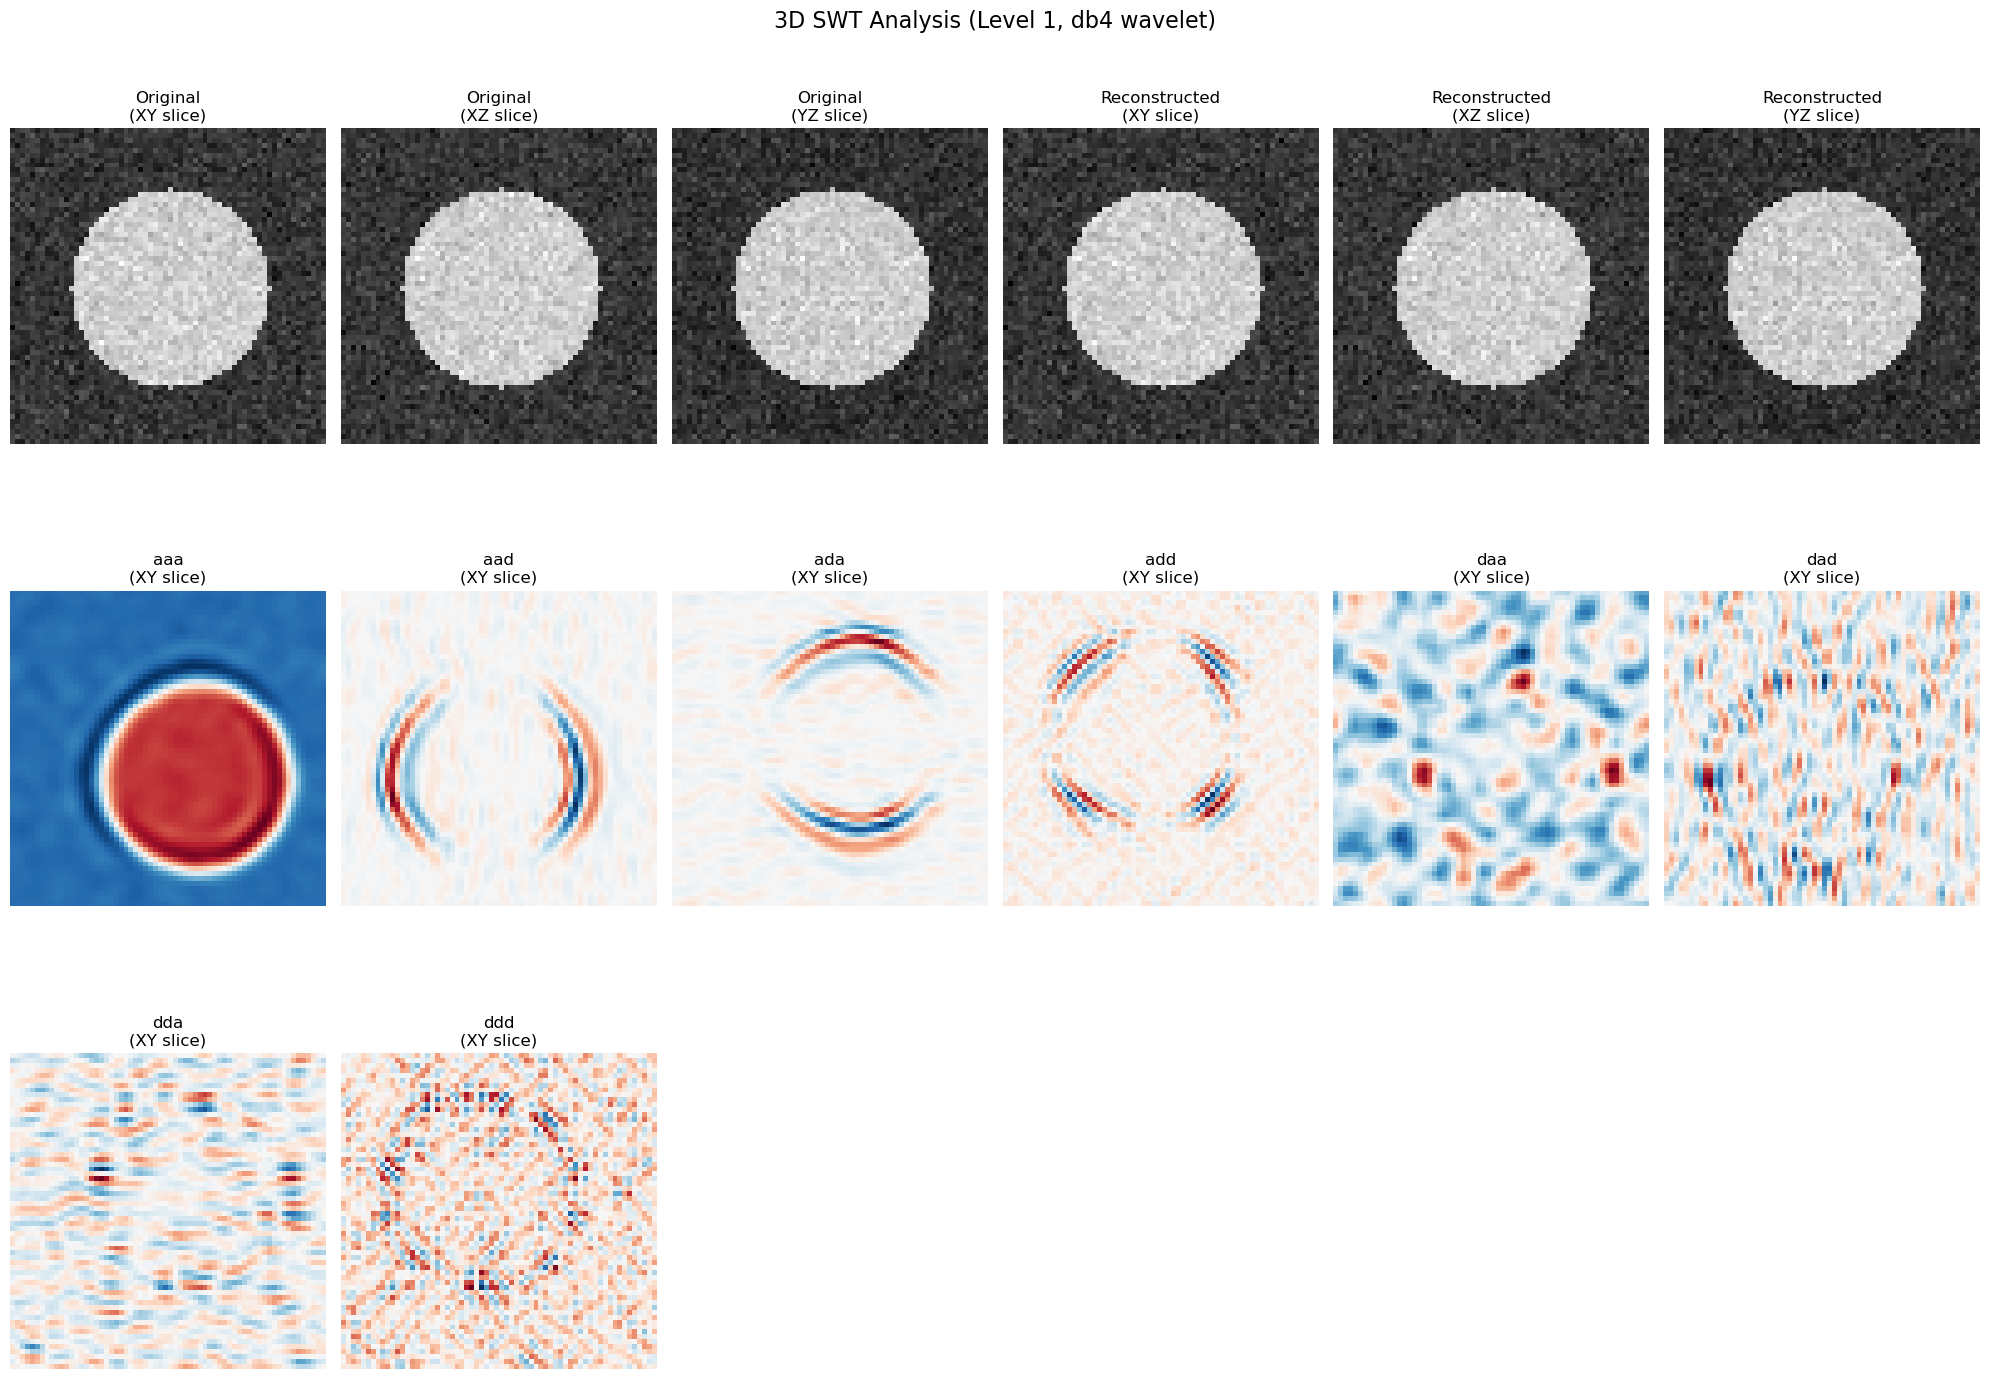


Energy Analysis (Level 1):
   aaa: Energy = 2023372.66, Ratio =  0.962
   aad: Energy = 18127.77, Ratio =  0.009
   ada: Energy = 17879.00, Ratio =  0.009
   add: Energy =  7063.75, Ratio =  0.003
   daa: Energy = 17967.03, Ratio =  0.009
   dad: Energy =  7017.96, Ratio =  0.003
   dda: Energy =  7115.57, Ratio =  0.003
   ddd: Energy =  4800.49, Ratio =  0.002
=== N-D SWT Denoising Demo ===
Clean volume shape: (32, 32, 32)
Noise level (std): 0.2
Original SNR: 10.31 dB
Denoised SNR: 9.23 dB
SNR improvement: -1.08 dB


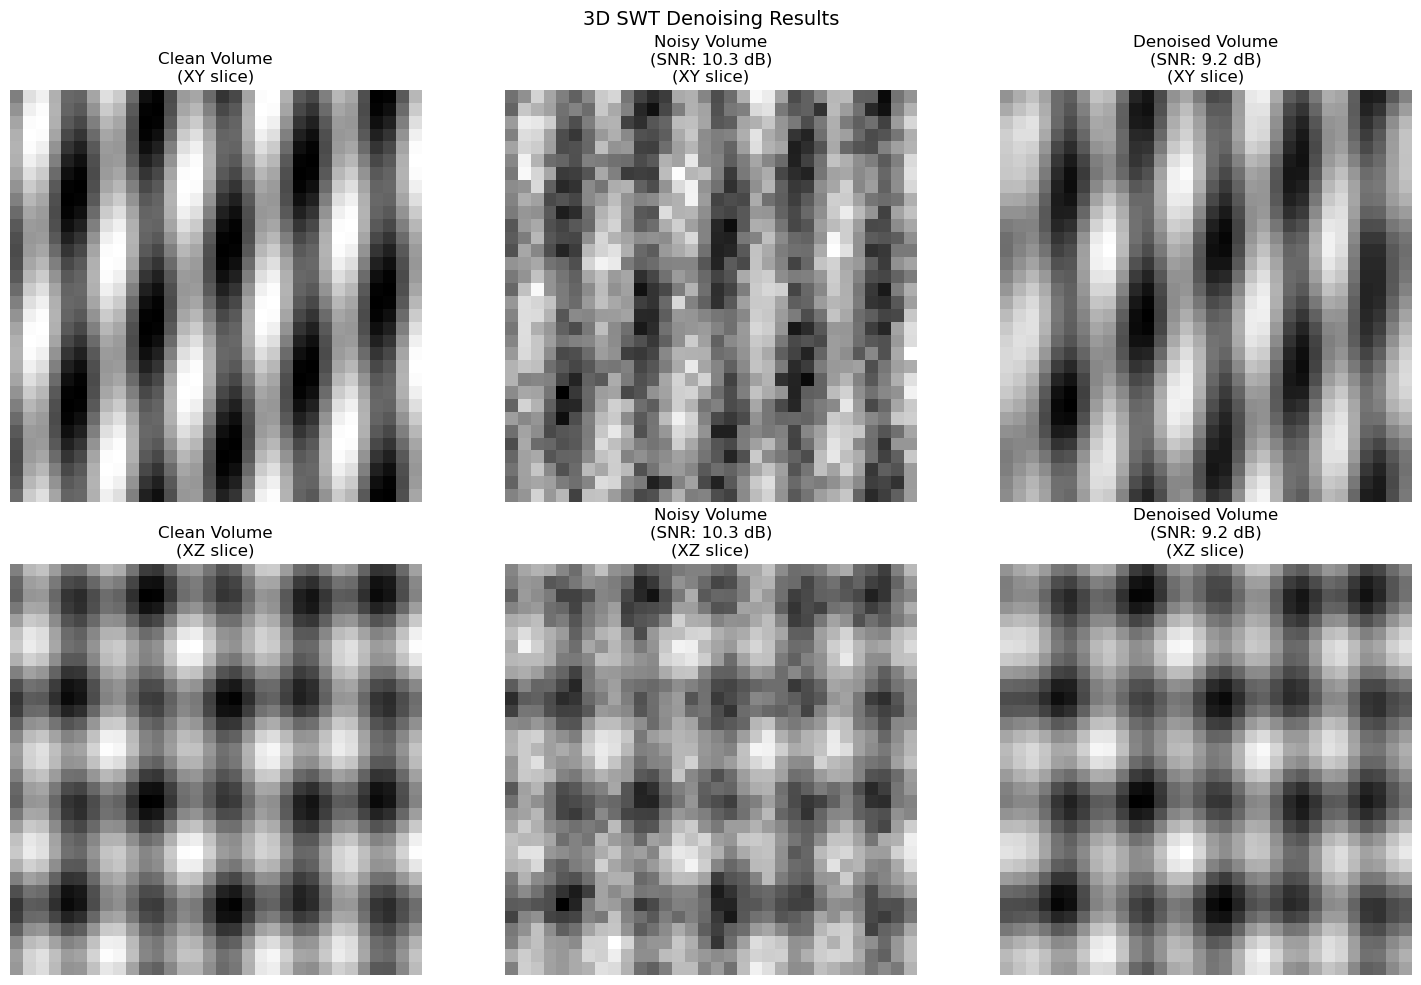

=== Advanced N-D SWT Applications ===

1. Video Denoising (3D: Height × Width × Time):
  Video shape: (16, 64, 64) (T×H×W)
  Video SNR - Original: 12.79 dB
  Video SNR - Denoised: 15.97 dB
  Improvement: 3.17 dB


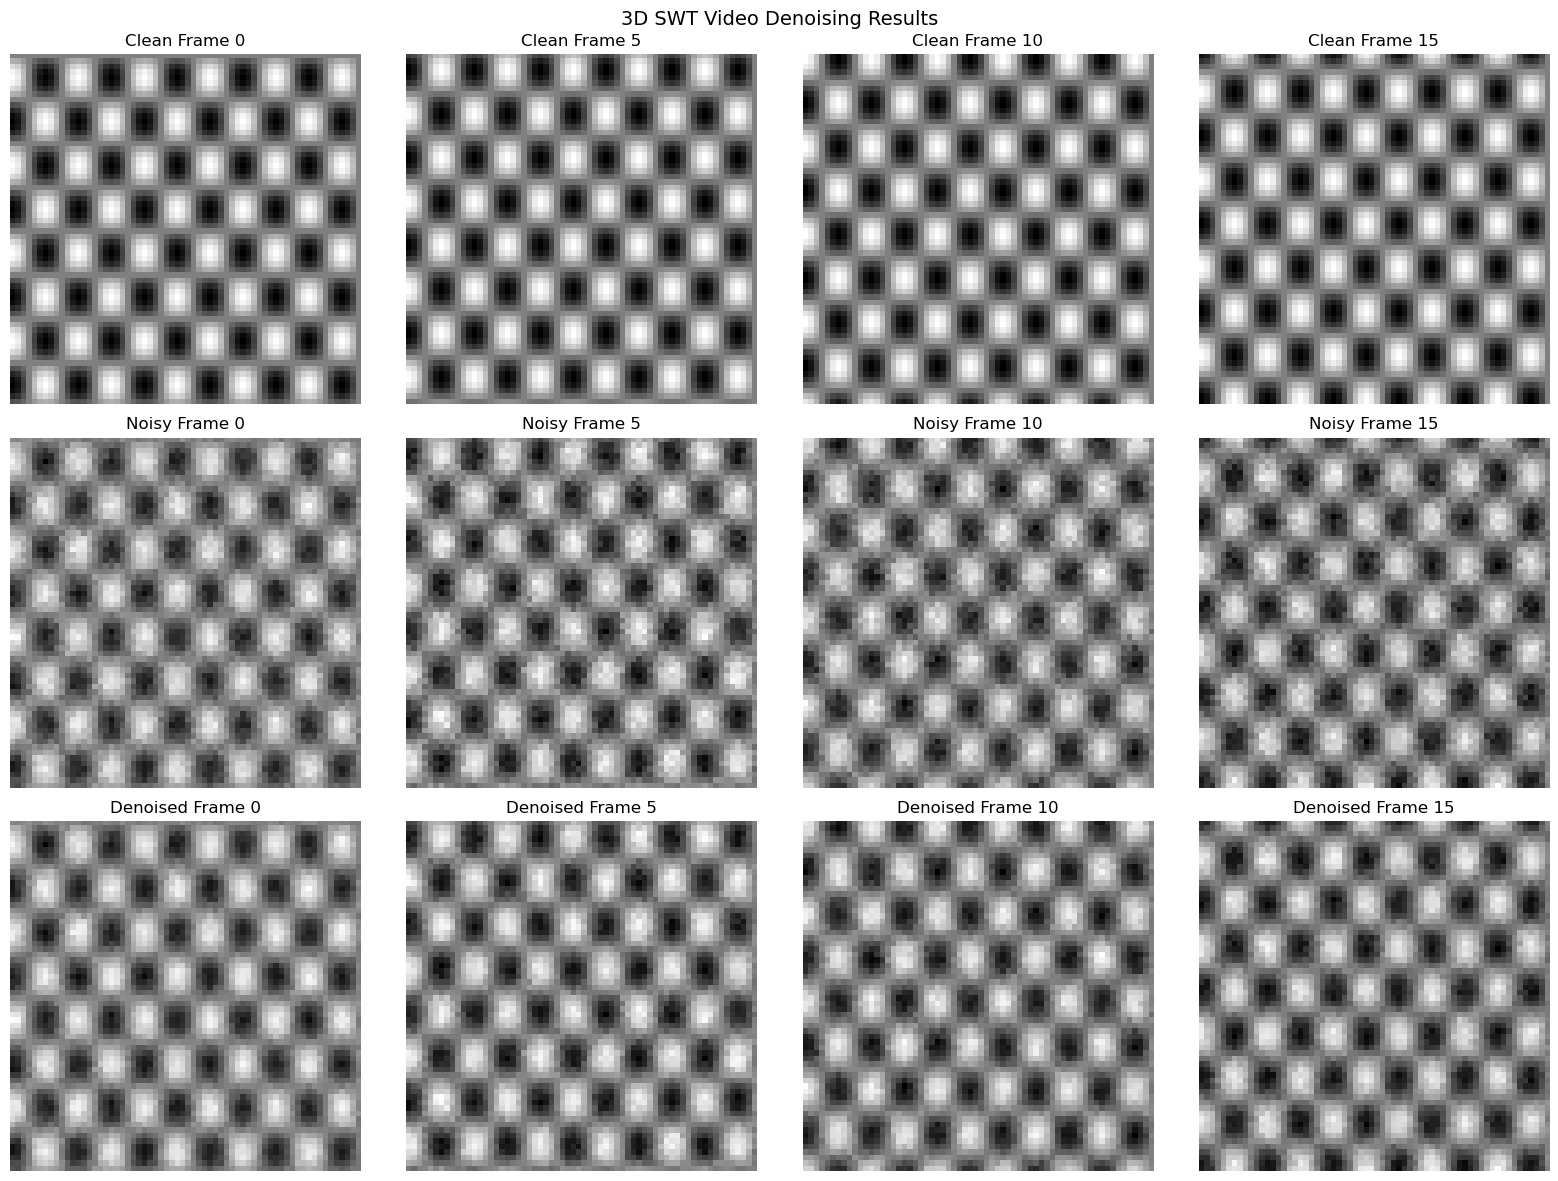


2. Hyperspectral Image Analysis (3D: H × W × Spectral):
  Hyperspectral data shape: (32, 32, 16) (H×W×Spectral)
  Number of coefficient subbands: 8
  aaa: Total energy = 30574.24
  aad: Total energy = 17731.56
  ada: Total energy = 399.57
  add: Total energy = 164.03
  daa: Total energy = 651.43
  dad: Total energy = 346.35
  dda: Total energy = 8.50
  ddd: Total energy = 3.49


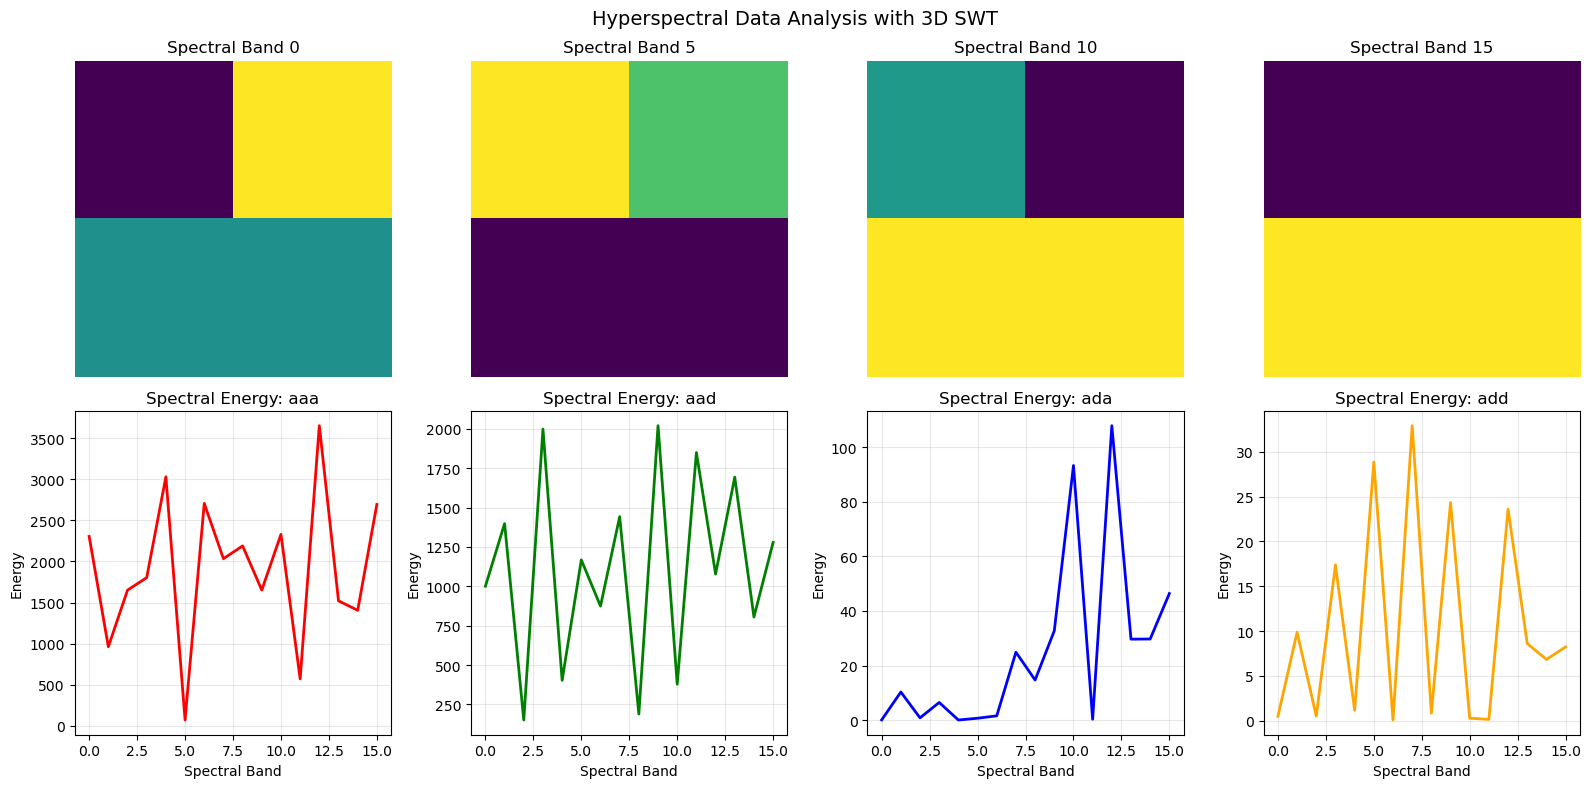

In [ ]:
import numpy as np
import pywt
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def swtn_comprehensive_demo():
    """
    Comprehensive demonstration of N-D SWT with various dimensional data.
    """
    print("=== N-Dimensional SWT Demo ===")
    
    # 3D Example: Synthetic volume data
    print("\n1. 3D SWT Example:")
    
    # Create 3D test data - a sphere with noise
    def create_3d_sphere(size=64, radius=20, noise_level=0.1):
        """Create a 3D sphere with Gaussian noise."""
        x, y, z = np.mgrid[0:size, 0:size, 0:size]
        center = size // 2
        sphere = ((x - center)**2 + (y - center)**2 + (z - center)**2) <= radius**2
        
        # Add Gaussian noise
        noise = np.random.normal(0, noise_level, sphere.shape)
        return sphere.astype(float) + noise
    
    np.random.seed(42)
    volume_3d = create_3d_sphere(64, 20, 0.1)
    
    print(f"  3D volume shape: {volume_3d.shape}")
    
    # Perform 3D SWT
    wavelet = 'db4'
    levels = 2
    coeffs_3d = pywt.swtn(volume_3d, wavelet, levels)
    
    print(f"  3D SWT completed: {levels} levels")
    print(f"  Number of coefficient arrays: {len(coeffs_3d)}")
    
    # Analyze 3D coefficients
    for level, coeff_dict in enumerate(coeffs_3d):
        print(f"  Level {level + 1}:")
        total_energy = 0
        for key, coeff_array in coeff_dict.items():
            energy = np.sum(coeff_array**2)
            total_energy += energy
            print(f"    {key}: shape={coeff_array.shape}, energy={energy:.2f}")
        print(f"    Total energy: {total_energy:.2f}")
    
    # Reconstruction
    reconstructed_3d = pywt.iswtn(coeffs_3d, wavelet)
    reconstruction_error_3d = np.max(np.abs(reconstructed_3d - volume_3d))
    print(f"  3D reconstruction error: {reconstruction_error_3d:.2e}")
    
    # 4D Example: Time series of images
    print("\n2. 4D SWT Example (Time-series of 2D images):")
    
    # Create 4D test data - rotating pattern over time
    def create_4d_timeseries(nt=16, nx=32, ny=32, nz=8):
        """Create 4D data representing evolving pattern."""
        t, x, y, z = np.mgrid[0:nt, 0:nx, 0:ny, 0:nz]
        
        # Rotating wave pattern
        data_4d = np.sin(2*np.pi * (x + y + t)/8) * np.cos(2*np.pi * z/4)
        return data_4d
    
    data_4d = create_4d_timeseries()
    print(f"  4D data shape: {data_4d.shape}")
    
    # Perform 4D SWT (limited levels due to memory)
    levels_4d = 1
    coeffs_4d = pywt.swtn(data_4d, wavelet, levels_4d)
    
    print(f"  4D SWT completed: {levels_4d} levels")
    print(f"  Number of 4D coefficient arrays: {len(coeffs_4d[0])}")
    
    # Analyze 4D coefficients
    coeff_dict_4d = coeffs_4d[0]
    for key, coeff_array in coeff_dict_4d.items():
        energy = np.sum(coeff_array**2)
        print(f"    {key}: shape={coeff_array.shape}, energy={energy:.2f}")
    
    # Reconstruction
    reconstructed_4d = pywt.iswtn(coeffs_4d, wavelet)
    reconstruction_error_4d = np.max(np.abs(reconstructed_4d - data_4d))
    print(f"  4D reconstruction error: {reconstruction_error_4d:.2e}")
    
    return {
        '3d_data': volume_3d,
        '3d_coeffs': coeffs_3d,
        '3d_reconstructed': reconstructed_3d,
        '4d_data': data_4d,
        '4d_coeffs': coeffs_4d,
        '4d_reconstructed': reconstructed_4d
    }

def visualize_3d_swt(volume, coeffs_3d, wavelet, level=0):
    """
    Visualize 3D SWT results using slice views and 3D plots.
    
    Parameters:
    -----------
    volume : ndarray
        Original 3D volume
    coeffs_3d : list
        3D SWT coefficients
    wavelet : str
        Wavelet used
    level : int
        Level to visualize (0 for first level)
    """
    print(f"=== 3D SWT Visualization (Level {level + 1}) ===")
    
    # Get coefficients for specified level
    coeff_dict = coeffs_3d[level]
    
    # Reconstruct volume
    reconstructed = pywt.iswtn(coeffs_3d, wavelet)
    
    # Create figure with multiple subplots
    fig = plt.figure(figsize=(20, 15))
    
    # Original volume - central slices
    mid_slice = volume.shape[0] // 2
    
    plt.subplot(3, 6, 1)
    plt.imshow(volume[mid_slice, :, :], cmap='gray')
    plt.title('Original\n(XY slice)')
    plt.axis('off')
    
    plt.subplot(3, 6, 2)
    plt.imshow(volume[:, mid_slice, :], cmap='gray')
    plt.title('Original\n(XZ slice)')
    plt.axis('off')
    
    plt.subplot(3, 6, 3)
    plt.imshow(volume[:, :, mid_slice], cmap='gray')
    plt.title('Original\n(YZ slice)')
    plt.axis('off')
    
    # Reconstructed volume - central slices
    plt.subplot(3, 6, 4)
    plt.imshow(reconstructed[mid_slice, :, :], cmap='gray')
    plt.title('Reconstructed\n(XY slice)')
    plt.axis('off')
    
    plt.subplot(3, 6, 5)
    plt.imshow(reconstructed[:, mid_slice, :], cmap='gray')
    plt.title('Reconstructed\n(XZ slice)')
    plt.axis('off')
    
    plt.subplot(3, 6, 6)
    plt.imshow(reconstructed[:, :, mid_slice], cmap='gray')
    plt.title('Reconstructed\n(YZ slice)')
    plt.savefig('./output/7.11_3d_swt_visualization.png', dpi=300)   
    plt.axis('off')
    
    # Coefficient subbands - show central slices
    subplot_idx = 7
    subband_keys = sorted(coeff_dict.keys())
    
    for i, key in enumerate(subband_keys[:12]):  # Show up to 12 subbands
        coeff = coeff_dict[key]
        mid_idx = coeff.shape[0] // 2
        
        row = (subplot_idx - 1) // 6
        col = (subplot_idx - 1) % 6
        
        if row < 3:  # Only plot if within our subplot grid
            plt.subplot(3, 6, subplot_idx)
            plt.imshow(coeff[mid_idx, :, :], cmap='RdBu_r')
            plt.title(f'{key}\n(XY slice)')
            plt.axis('off')
            subplot_idx += 1
    
    plt.suptitle(f'3D SWT Analysis (Level {level + 1}, {wavelet} wavelet)', fontsize=16)
    plt.tight_layout()
    plt.savefig('./output/7.12_3d_swt_detailed.png', dpi=300)
    plt.show()
    
    # Energy analysis
    print(f"\nEnergy Analysis (Level {level + 1}):")
    total_energy = sum(np.sum(coeff**2) for coeff in coeff_dict.values())
    
    for key, coeff in sorted(coeff_dict.items()):
        energy = np.sum(coeff**2)
        energy_ratio = energy / total_energy
        print(f"  {key:>4}: Energy = {energy:8.2f}, Ratio = {energy_ratio:6.3f}")

def swtn_denoising_demo():
    """
    Demonstrate N-D SWT for volumetric data denoising.
    """
    print("=== N-D SWT Denoising Demo ===")
    
    # Create clean 3D signal
    def create_clean_3d_signal(size=32):
        """Create a clean 3D signal with multiple frequency components."""
        x, y, z = np.mgrid[0:size, 0:size, 0:size]
        
        # Multiple frequency components
        signal = (np.sin(2*np.pi * x / 8) * np.cos(2*np.pi * y / 12) +
                 0.5 * np.sin(2*np.pi * z / 6) +
                 0.3 * np.sin(2*np.pi * (x + y + z) / 16))
        
        return signal
    
    # Generate clean and noisy data
    np.random.seed(42)
    clean_volume = create_clean_3d_signal(32)
    noise_level = 0.2
    noise = np.random.normal(0, noise_level, clean_volume.shape)
    noisy_volume = clean_volume + noise
    
    print(f"Clean volume shape: {clean_volume.shape}")
    print(f"Noise level (std): {noise_level}")
    
    # 3D SWT decomposition
    wavelet = 'db6'
    levels = 2
    coeffs = pywt.swtn(noisy_volume, wavelet, levels)
    
    # Denoising via soft thresholding
    def calculate_3d_snr(clean, noisy):
        """Calculate 3D signal-to-noise ratio."""
        signal_power = np.mean(clean**2)
        noise_power = np.mean((clean - noisy)**2)
        return 10 * np.log10(signal_power / noise_power) if noise_power > 0 else float('inf')
    
    original_snr = calculate_3d_snr(clean_volume, noisy_volume)
    print(f"Original SNR: {original_snr:.2f} dB")
    
    # Soft thresholding
    threshold = noise_level * np.sqrt(2 * np.log(noisy_volume.size))
    coeffs_denoised = []
    
    for level, coeff_dict in enumerate(coeffs):
        denoised_dict = {}
        for key, coeff in coeff_dict.items():
            # Apply different thresholds based on subband type
            if 'LLL' in key:  # Approximation - gentle thresholding
                denoised_dict[key] = pywt.threshold(coeff, threshold * 0.5, mode='soft')
            else:  # Detail subbands - stronger thresholding
                scale_factor = 2**level
                denoised_dict[key] = pywt.threshold(coeff, threshold * scale_factor, mode='soft')
        
        coeffs_denoised.append(denoised_dict)
    
    # Reconstruct denoised volume
    denoised_volume = pywt.iswtn(coeffs_denoised, wavelet)
    denoised_snr = calculate_3d_snr(clean_volume, denoised_volume)
    
    print(f"Denoised SNR: {denoised_snr:.2f} dB")
    print(f"SNR improvement: {denoised_snr - original_snr:.2f} dB")
    
    # Visualization
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    
    # Central slice index
    mid_slice = clean_volume.shape[0] // 2
    
    volumes = [
        (clean_volume, 'Clean Volume'),
        (noisy_volume, f'Noisy Volume\n(SNR: {original_snr:.1f} dB)'),
        (denoised_volume, f'Denoised Volume\n(SNR: {denoised_snr:.1f} dB)')
    ]
    
    for i, (volume, title) in enumerate(volumes):
        # XY slice
        axes[0, i].imshow(volume[mid_slice, :, :], cmap='gray')
        axes[0, i].set_title(f'{title}\n(XY slice)')
        axes[0, i].axis('off')
        
        # XZ slice
        axes[1, i].imshow(volume[:, mid_slice, :], cmap='gray')
        axes[1, i].set_title(f'{title}\n(XZ slice)')
        axes[1, i].axis('off')
    
    plt.suptitle('3D SWT Denoising Results', fontsize=14)
    plt.tight_layout()
    plt.show()
    
    return {
        'clean': clean_volume,
        'noisy': noisy_volume,
        'denoised': denoised_volume,
        'original_snr': original_snr,
        'denoised_snr': denoised_snr,
        'coefficients': coeffs,
        'denoised_coefficients': coeffs_denoised
    }

def advanced_nd_applications():
    """
    Demonstrate advanced N-D SWT applications.
    """
    print("=== Advanced N-D SWT Applications ===")
    
    # Application 1: Video denoising (3D: space + time)
    print("\n1. Video Denoising (3D: Height × Width × Time):")
    
    def create_synthetic_video(nt=16, nx=64, ny=64):
        """Create synthetic video with moving patterns."""
        t, x, y = np.mgrid[0:nt, 0:nx, 0:ny]
        
        # Moving wave pattern
        video = np.sin(2*np.pi * (x + 2*t) / 16) * np.cos(2*np.pi * y / 12)
        
        # Add motion blur effect
        for frame in range(nt-1):
            video[frame+1] = 0.7 * video[frame+1] + 0.3 * video[frame]
        
        return video
    
    np.random.seed(42)
    clean_video = create_synthetic_video()
    noise_video = clean_video + 0.1 * np.random.randn(*clean_video.shape)
    
    print(f"  Video shape: {clean_video.shape} (T×H×W)")
    
    # 3D SWT on video
    coeffs_video = pywt.swtn(noise_video, 'db4', 2)
    
    # Simple denoising
    threshold = 0.05
    coeffs_video_denoised = []
    
    for coeff_dict in coeffs_video:
        denoised_dict = {}
        for key, coeff in coeff_dict.items():
            if key == 'LLL':
                denoised_dict[key] = coeff  # Keep approximation
            else:
                denoised_dict[key] = pywt.threshold(coeff, threshold, mode='soft')
        coeffs_video_denoised.append(denoised_dict)
    
    denoised_video = pywt.iswtn(coeffs_video_denoised, 'db4')
    
    # Calculate improvement
    video_snr_orig = 10 * np.log10(np.mean(clean_video**2) / np.mean((clean_video - noise_video)**2))
    video_snr_denoised = 10 * np.log10(np.mean(clean_video**2) / np.mean((clean_video - denoised_video)**2))
    
    print(f"  Video SNR - Original: {video_snr_orig:.2f} dB")
    print(f"  Video SNR - Denoised: {video_snr_denoised:.2f} dB")
    print(f"  Improvement: {video_snr_denoised - video_snr_orig:.2f} dB")
    
    # Visualization - show few frames
    fig, axes = plt.subplots(3, 4, figsize=(16, 12))
    frames_to_show = [0, 5, 10, 15]
    
    for i, frame_idx in enumerate(frames_to_show):
        # Clean frame
        axes[0, i].imshow(clean_video[frame_idx], cmap='gray')
        axes[0, i].set_title(f'Clean Frame {frame_idx}')
        axes[0, i].axis('off')
        
        # Noisy frame
        axes[1, i].imshow(noise_video[frame_idx], cmap='gray')
        axes[1, i].set_title(f'Noisy Frame {frame_idx}')
        axes[1, i].axis('off')
        
        # Denoised frame
        axes[2, i].imshow(denoised_video[frame_idx], cmap='gray')
        axes[2, i].set_title(f'Denoised Frame {frame_idx}')
        axes[2, i].axis('off')
    
    plt.suptitle('3D SWT Video Denoising Results', fontsize=14)
    plt.tight_layout()
    plt.savefig('./output/7.13_3d_swt_video_denoising.png', dpi=300)
    plt.show()
    
    # Application 2: Hyperspectral image analysis (3D: Height × Width × Spectral)
    print("\n2. Hyperspectral Image Analysis (3D: H × W × Spectral):")
    
    def create_hyperspectral_data(nh=32, nw=32, nspec=16):
        """Create synthetic hyperspectral data."""
        h, w, spec = np.mgrid[0:nh, 0:nw, 0:nspec]
        
        # Different spectral signatures for different spatial regions
        data = np.zeros((nh, nw, nspec))
        
        # Region 1: Top-left
        data[:nh//2, :nw//2, :] = np.sin(2*np.pi * spec[:nh//2, :nw//2, :] / 4)
        
        # Region 2: Top-right  
        data[:nh//2, nw//2:, :] = np.cos(2*np.pi * spec[:nh//2, nw//2:, :] / 6)
        
        # Region 3: Bottom
        data[nh//2:, :, :] = 0.5 * (np.sin(2*np.pi * spec[nh//2:, :, :] / 3) + 
                                   np.cos(2*np.pi * spec[nh//2:, :, :] / 8))
        
        return data
    
    hyperspectral = create_hyperspectral_data()
    print(f"  Hyperspectral data shape: {hyperspectral.shape} (H×W×Spectral)")
    
    # 3D SWT on hyperspectral data
    coeffs_hyper = pywt.swtn(hyperspectral, 'db6', 1)
    
    # Analyze spectral components
    coeff_dict = coeffs_hyper[0]
    print(f"  Number of coefficient subbands: {len(coeff_dict)}")
    
    # Extract spectral features
    spectral_energies = {}
    for key, coeff in coeff_dict.items():
        # Sum energy across spatial dimensions for each spectral band
        spectral_energy = np.sum(coeff**2, axis=(0, 1))
        spectral_energies[key] = spectral_energy
        print(f"  {key}: Total energy = {np.sum(spectral_energy):.2f}")
    
    # Visualization - spectral signatures
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    
    # Show few spectral bands as images
    bands_to_show = [0, 5, 10, 15]
    for i, band in enumerate(bands_to_show):
        if band < hyperspectral.shape[2]:
            axes[0, i].imshow(hyperspectral[:, :, band], cmap='viridis')
            axes[0, i].set_title(f'Spectral Band {band}')
            axes[0, i].axis('off')
    
    # Show spectral energy signatures for different subbands
    spectral_range = np.arange(hyperspectral.shape[2])
    colors = ['red', 'green', 'blue', 'orange']
    
    for i, (key, energy) in enumerate(list(spectral_energies.items())[:4]):
        axes[1, i].plot(spectral_range, energy, color=colors[i % len(colors)], linewidth=2)
        axes[1, i].set_title(f'Spectral Energy: {key}')
        axes[1, i].set_xlabel('Spectral Band')
        axes[1, i].set_ylabel('Energy')
        axes[1, i].grid(True, alpha=0.3)
    
    plt.suptitle('Hyperspectral Data Analysis with 3D SWT', fontsize=14)
    plt.tight_layout()
    plt.savefig('./output/7.14_3d_swt_hyperspectral_analysis.png', dpi=300)
    plt.show()
    
    return {
        'video_clean': clean_video,
        'video_noisy': noise_video,
        'video_denoised': denoised_video,
        'video_snr_improvement': video_snr_denoised - video_snr_orig,
        'hyperspectral': hyperspectral,
        'hyperspectral_coeffs': coeffs_hyper,
        'spectral_energies': spectral_energies
    }

# Run N-D demonstrations
if __name__ == "__main__":
    # Basic N-D SWT demo
    nd_results = swtn_comprehensive_demo()
    
    # Visualize 3D results
    if '3d_data' in nd_results:
        visualize_3d_swt(
            nd_results['3d_data'],
            nd_results['3d_coeffs'],
            'db4'
        )
    
    # 3D denoising demo
    denoising_3d_results = swtn_denoising_demo()
    
    # Advanced applications
    advanced_results = advanced_nd_applications()